# Entrenamiento de modelos Multicanal (EEG + EOG)

**Maestría en Inteligencia Artificial MAIA**

***Estudiantes:***
- María José García (mj.garciab1@uniandes.edu.co)
- Daniel Osuna (d.osuna@uniandes.edu.co)
- Gabriel Vizcaya (g.vizcaya@uniandes.edu.co)
- Joel Vargas (js.vargasl1@uniandes.edu.co)

Entrenamiento supervisado con `XGBClassifier`, `Random Forest`, `Arbol de Decisiones`y `LightGBM` usando `train_multicanal.csv` y `test_multicanal.csv`. El dataset multicanal conserva un único esquema de columnas para soportar inferencia cuando alguno de los canales `EEG` está presente y `EOG horizontal` opcional.

## Librerias

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))
from src.data.segmentation import CLASS_NAMES, INT_TO_CLASS


warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuración

El entrenamiento excluye identificadores y columnas de control que pueden generar fuga de información (`recording_id`, `subject_code`, `split`, `epoch_idx_in_recording`). Tampoco se usan las columnas de disponibilidad de canales (`has_*`, `channel_count`, `channel_combo`): las features de un canal ausente quedan en `NaN`, así que el modelo ya sabe qué canales llegaron. Las features son 35: 14 por cada EEG Y 7 del EOG.

In [2]:
RANDOM_STATE = 42
CV_SPLITS = 5
N_ITER_SEARCH = 10
SCORING = "f1_macro"

TARGET_COLUMN = "y"
ID_COLUMNS = ["recording_id", "subject_code"]
CONTROL_COLUMNS = ["split", "epoch_idx_in_recording", "channel_combo", "channel_count", "has_eeg_fpz_cz", "has_eeg_pz_oz", "has_eog_horizontal",]
CATEGORICAL_COLUMNS = []

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data" / "processed" / "train_multicanal.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "modelos"
MODEL_DIR.mkdir(exist_ok=True)

TRAIN_PATH = DATA_DIR / "train_multicanal.csv"
TEST_PATH = DATA_DIR / "test_multicanal.csv"

COMPARISON_PATH = MODEL_DIR / "model_comparison_multicanal.csv"
COMPARISON_BY_COMBO_PATH = MODEL_DIR / "model_comparison_by_channel_combo_multicanal.csv"


def get_artifact_paths(model_slug):
    """Rutas de artefactos de un modelo, p. ej. `best-xgboost-multicanal.joblib`."""
    return {
        "joblib": MODEL_DIR / f"best-{model_slug}-multicanal.joblib",
        "info": MODEL_DIR / f"model_info_{model_slug}_multicanal.json",
        "metrics_by_combo": MODEL_DIR / f"metrics_by_channel_combo_{model_slug}_multicanal.csv",
        "per_class_by_combo": MODEL_DIR / f"per_class_metrics_by_channel_combo_{model_slug}_multicanal.csv",
        "feature_importance": MODEL_DIR / f"feature_importance_{model_slug}_multicanal.csv",
    }

## Carga de datos

In [3]:
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print(f"Train shape: {train_df.shape}")
print(f"Test shape:  {test_df.shape}")

display(train_df.head())
display(train_df[TARGET_COLUMN].value_counts().sort_index().rename("train_count"))
display(test_df[TARGET_COLUMN].value_counts().sort_index().rename("test_count"))
display(train_df["channel_combo"].value_counts().rename("train_rows_by_combo"))
display(test_df["channel_combo"].value_counts().rename("test_rows_by_combo"))

Train shape: (901632, 45)
Test shape:  (269910, 45)


,channel_combo,channel_count,split,epoch_idx_in_recording,has_eeg_fpz_cz,has_eeg_pz_oz,has_eog_horizontal,recording_id,subject_code,y,...,EEG_Pz-Oz__theta_alpha_ratio,EEG_Pz-Oz__theta_power_abs,EEG_Pz-Oz__theta_power_rel,EOG_horizontal__beta_power_abs,EOG_horizontal__delta_power_abs,EOG_horizontal__delta_power_rel,EOG_horizontal__hjorth_mobility,EOG_horizontal__kurtosis,EOG_horizontal__p2p_robust,EOG_horizontal__saccade_count
0,eeg_fpz_cz,1,train,0,True,False,False,SC4001E0,0,W,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,eeg_fpz_cz,1,train,1,True,False,False,SC4001E0,0,W,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,eeg_fpz_cz,1,train,2,True,False,False,SC4001E0,0,W,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,eeg_fpz_cz,1,train,3,True,False,False,SC4001E0,0,W,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,eeg_fpz_cz,1,train,4,True,False,False,SC4001E0,0,W,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


y
N1      98670
N2     321558
N3      63474
REM    120540
W      297390
Name: train_count, dtype: int64

y
N1     30462
N2     93234
N3     14760
REM    34470
W      96984
Name: test_count, dtype: int64

channel_combo
eeg_fpz_cz                               150272
eeg_pz_oz                                150272
eeg_fpz_cz__eeg_pz_oz                    150272
eeg_fpz_cz__eog_horizontal               150272
eeg_pz_oz__eog_horizontal                150272
eeg_fpz_cz__eeg_pz_oz__eog_horizontal    150272
Name: train_rows_by_combo, dtype: int64

channel_combo
eeg_fpz_cz                               44985
eeg_pz_oz                                44985
eeg_fpz_cz__eeg_pz_oz                    44985
eeg_fpz_cz__eog_horizontal               44985
eeg_pz_oz__eog_horizontal                44985
eeg_fpz_cz__eeg_pz_oz__eog_horizontal    44985
Name: test_rows_by_combo, dtype: int64

## Preparación de matrices

In [4]:
missing_columns = set(train_df.columns) ^ set(test_df.columns)
if missing_columns:
    raise ValueError(f"Train y test no tienen las mismas columnas: {missing_columns}")

excluded_columns = [TARGET_COLUMN, *ID_COLUMNS, *CONTROL_COLUMNS]
base_feature_columns = [column for column in train_df.columns if column not in excluded_columns]

X_train_raw = train_df[base_feature_columns].copy()
X_test_raw = test_df[base_feature_columns].copy()

X_train = pd.get_dummies(X_train_raw, columns=CATEGORICAL_COLUMNS, dtype=np.int8)
X_test = pd.get_dummies(X_test_raw, columns=CATEGORICAL_COLUMNS, dtype=np.int8)
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

for df in (X_train, X_test):
    bool_columns = df.select_dtypes(include="bool").columns
    df[bool_columns] = df[bool_columns].astype(np.int8)

feature_columns = X_train.columns.tolist()

y_train_names = train_df[TARGET_COLUMN].map(INT_TO_CLASS).fillna(train_df[TARGET_COLUMN]).astype(str)
y_test_names = test_df[TARGET_COLUMN].map(INT_TO_CLASS).fillna(test_df[TARGET_COLUMN]).astype(str)

label_encoder = LabelEncoder()
label_encoder.fit(CLASS_NAMES)
y_train = label_encoder.transform(y_train_names)
y_test = label_encoder.transform(y_test_names)
class_labels = np.array(CLASS_NAMES)

groups = train_df["subject_code"].astype(str).to_numpy()
sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

print(f"Número de features: {len(feature_columns)}")
print(f"Clases: {class_labels.tolist()}")
print(f"Número de pacientes/grupos en train: {pd.Series(groups).nunique()}")
print(f"Columnas excluidas: {excluded_columns}")
display(pd.Series(feature_columns, name="features"))

Número de features: 35
Clases: ['W', 'N1', 'N2', 'N3', 'REM']
Número de pacientes/grupos en train: 62
Columnas excluidas: ['y', 'recording_id', 'subject_code', 'split', 'epoch_idx_in_recording', 'channel_combo', 'channel_count', 'has_eeg_fpz_cz', 'has_eeg_pz_oz', 'has_eog_horizontal']


0         EEG_Fpz-Cz__alpha_power_abs
1         EEG_Fpz-Cz__alpha_power_rel
2          EEG_Fpz-Cz__beta_power_abs
3          EEG_Fpz-Cz__beta_power_rel
4       EEG_Fpz-Cz__delta_alpha_ratio
5         EEG_Fpz-Cz__delta_power_abs
6         EEG_Fpz-Cz__delta_power_rel
7                   EEG_Fpz-Cz__sef95
8         EEG_Fpz-Cz__sigma_power_abs
9         EEG_Fpz-Cz__sigma_power_rel
10       EEG_Fpz-Cz__spectral_entropy
11      EEG_Fpz-Cz__theta_alpha_ratio
12        EEG_Fpz-Cz__theta_power_abs
13        EEG_Fpz-Cz__theta_power_rel
14         EEG_Pz-Oz__alpha_power_abs
15         EEG_Pz-Oz__alpha_power_rel
16          EEG_Pz-Oz__beta_power_abs
17          EEG_Pz-Oz__beta_power_rel
18       EEG_Pz-Oz__delta_alpha_ratio
19         EEG_Pz-Oz__delta_power_abs
20         EEG_Pz-Oz__delta_power_rel
21                   EEG_Pz-Oz__sef95
22         EEG_Pz-Oz__sigma_power_abs
23         EEG_Pz-Oz__sigma_power_rel
24        EEG_Pz-Oz__spectral_entropy
25       EEG_Pz-Oz__theta_alpha_ratio
26         E

In [5]:
X_train.head()

,EEG_Fpz-Cz__alpha_power_abs,EEG_Fpz-Cz__alpha_power_rel,EEG_Fpz-Cz__beta_power_abs,EEG_Fpz-Cz__beta_power_rel,EEG_Fpz-Cz__delta_alpha_ratio,EEG_Fpz-Cz__delta_power_abs,EEG_Fpz-Cz__delta_power_rel,EEG_Fpz-Cz__sef95,EEG_Fpz-Cz__sigma_power_abs,EEG_Fpz-Cz__sigma_power_rel,...,EEG_Pz-Oz__theta_alpha_ratio,EEG_Pz-Oz__theta_power_abs,EEG_Pz-Oz__theta_power_rel,EOG_horizontal__beta_power_abs,EOG_horizontal__delta_power_abs,EOG_horizontal__delta_power_rel,EOG_horizontal__hjorth_mobility,EOG_horizontal__kurtosis,EOG_horizontal__p2p_robust,EOG_horizontal__saccade_count
0,4.132619,0.010247,8.005553,0.019849,84.448240,348.99240,0.865313,6.25,3.506238,0.008694,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4.140185,0.007408,8.547596,0.015294,118.638700,491.18616,0.878890,5.25,1.985889,0.003553,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4.420617,0.005397,6.731600,0.008219,165.688390,732.44490,0.894271,4.75,2.095118,0.002558,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5.159684,0.008336,13.300922,0.021489,104.480900,539.08844,0.870950,6.00,3.834363,0.006195,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4.296539,0.008489,8.148181,0.016099,103.137566,443.13455,0.875535,5.75,2.656312,0.005248,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Búsqueda de hiperparámetros con validación cruzada

Los cuatro modelos (`XGBoost`, `LightGBM`, `Random Forest` y `Árbol de Decisión`) se entrenan con el mismo protocolo para que la comparación sea justa:

- `RandomizedSearchCV` con `N_ITER_SEARCH` combinaciones por modelo.
- CV estratificada por clase y agrupada por `subject_code` (`StratifiedGroupKFold`). Así, todas las épocas de un mismo paciente quedan completas en train o validation dentro de cada fold. Los folds son idénticos para todos los modelos.
- Pesos de muestra balanceados (`sample_weight`) para compensar el desbalance de clases.
- Selección del mejor modelo por `f1_macro` promedio en la validación cruzada y evaluación final en `test_multicanal.csv`.

Las funciones siguientes encapsulan la búsqueda, la evaluación y el guardado de artefactos, para aplicar exactamente el mismo flujo a cada modelo.

In [6]:
cv = StratifiedGroupKFold(
    n_splits=CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

LABEL_IDS = label_encoder.transform(class_labels)
CV_SUMMARY_COLUMNS = [
    "rank_test_score",
    "mean_test_score",
    "std_test_score",
    "mean_train_score",
    "std_train_score",
    "params",
]

results = {}


def run_search(model_name, estimator, param_distributions):
    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_distributions,
        n_iter=N_ITER_SEARCH,
        scoring=SCORING,
        cv=cv,
        verbose=2,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
    )
    search.fit(X_train, y_train, groups=groups, sample_weight=sample_weights)

    print(f"[{model_name}] Mejor {SCORING} CV: {search.best_score_}")
    print("Mejores hiperparámetros:")
    display(search.best_params_)
    return search


def show_cv_results(search, top_n=10):
    cv_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
    display(cv_results[CV_SUMMARY_COLUMNS].head(top_n))
    return cv_results

In [7]:
def evaluate_predictions(y_true, y_hat, labels, prefix=None):
    return {
        "channel_combo": prefix,
        "support": len(y_true),
        "accuracy": accuracy_score(y_true, y_hat),
        "macro_f1": f1_score(y_true, y_hat, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_hat),
        "cohens_kappa": cohen_kappa_score(y_true, y_hat),
    }


def evaluate_global(model_name, search):
    y_pred = search.best_estimator_.predict(X_test)

    precision, recall, f1, support = precision_recall_fscore_support(
        y_test,
        y_pred,
        labels=LABEL_IDS,
        zero_division=0,
    )

    metrics = {
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "cohens_kappa": cohen_kappa_score(y_test, y_pred),
        "best_cv_macro_f1": search.best_score_,
        "best_params": search.best_params_,
    }

    per_class_metrics = pd.DataFrame(
        {
            "class": class_labels,
            "precision_per_class": precision,
            "recall_per_class": recall,
            "f1_per_class": f1,
            "support": support,
        }
    )

    print(f"=== {model_name} - evaluación global en test ===")
    display(pd.Series(metrics, name="value"))
    display(per_class_metrics)
    print(classification_report(y_test, y_pred, labels=LABEL_IDS, target_names=[str(label) for label in class_labels], zero_division=0))
    return y_pred, metrics, per_class_metrics


def evaluate_by_combo(model_name, y_pred):
    combo_metric_rows = []
    combo_per_class_rows = []

    test_eval_df = test_df[["channel_combo", "recording_id", "subject_code", TARGET_COLUMN]].copy()
    test_eval_df["y_true"] = y_test
    test_eval_df["y_pred"] = y_pred

    combo_metric_rows.append(evaluate_predictions(y_test, y_pred, LABEL_IDS, prefix="overall"))

    for combo_name, combo_df in test_eval_df.groupby("channel_combo", sort=True):
        combo_y_true = combo_df["y_true"].to_numpy()
        combo_y_pred = combo_df["y_pred"].to_numpy()
        combo_metric_rows.append(evaluate_predictions(combo_y_true, combo_y_pred, LABEL_IDS, prefix=combo_name))

        p, r, f, s = precision_recall_fscore_support(
            combo_y_true,
            combo_y_pred,
            labels=LABEL_IDS,
            zero_division=0,
        )
        for class_name, precision_i, recall_i, f1_i, support_i in zip(class_labels, p, r, f, s):
            combo_per_class_rows.append(
                {
                    "channel_combo": combo_name,
                    "class": class_name,
                    "precision_per_class": precision_i,
                    "recall_per_class": recall_i,
                    "f1_per_class": f1_i,
                    "support": support_i,
                }
            )

    metrics_by_combo = pd.DataFrame(combo_metric_rows).sort_values("channel_combo")
    per_class_by_combo = pd.DataFrame(combo_per_class_rows).sort_values(["channel_combo", "class"])

    display(metrics_by_combo)
    display(per_class_by_combo)

    plt.figure(figsize=(10, 5))
    sns.barplot(data=metrics_by_combo[metrics_by_combo["channel_combo"] != "overall"], x="channel_combo", y="macro_f1", color="#4C78A8")
    plt.title(f"Macro F1 por combinación de canales - {model_name}")
    plt.xlabel("Combinación de canales")
    plt.ylabel("Macro F1")
    plt.xticks(rotation=30, ha="right")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()
    return test_eval_df, metrics_by_combo, per_class_by_combo


def plot_confusion_matrices(model_name, test_eval_df):
    conf_matrix = confusion_matrix(test_eval_df["y_true"], test_eval_df["y_pred"], labels=LABEL_IDS)
    conf_matrix_df = pd.DataFrame(conf_matrix, index=class_labels, columns=class_labels)

    plt.figure(figsize=(8, 6))
    sns.heatmap(conf_matrix_df, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(f"Matriz de confusión global - {model_name} multicanal")
    plt.xlabel("Predicción")
    plt.ylabel("Clase real")
    plt.tight_layout()
    plt.show()
    display(conf_matrix_df)

    for combo_name, combo_df in test_eval_df.groupby("channel_combo", sort=True):
        combo_conf_matrix = confusion_matrix(
            combo_df["y_true"],
            combo_df["y_pred"],
            labels=LABEL_IDS,
        )
        combo_conf_matrix_df = pd.DataFrame(combo_conf_matrix, index=class_labels, columns=class_labels)
        plt.figure(figsize=(7, 5))
        sns.heatmap(combo_conf_matrix_df, annot=True, fmt="d", cmap="Blues", cbar=False)
        plt.title(f"Matriz de confusión - {model_name} - {combo_name}")
        plt.xlabel("Predicción")
        plt.ylabel("Clase real")
        plt.tight_layout()
        plt.show()
        display(combo_conf_matrix_df)


def plot_feature_importance(model_name, model, top_n=30):
    feature_importance = pd.DataFrame(
        {
            "feature": feature_columns,
            "importance": model.feature_importances_,
        }
    ).sort_values("importance", ascending=False)

    plt.figure(figsize=(10, 10))
    sns.barplot(data=feature_importance.head(top_n), x="importance", y="feature", color="#4C78A8")
    plt.title(f"Top {top_n} importancia de variables - {model_name} multicanal")
    plt.xlabel("Importancia")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

    display(feature_importance)
    return feature_importance


def save_artifacts(model_name, model_slug, search, metrics, metrics_by_combo, per_class_by_combo, feature_importance):
    paths = get_artifact_paths(model_slug)
    best_model = search.best_estimator_

    joblib.dump(
        {
            "model": best_model,
            "label_encoder": label_encoder,
            "feature_columns": feature_columns,
            "excluded_columns": excluded_columns,
            "categorical_columns": CATEGORICAL_COLUMNS,
            "class_labels": class_labels.tolist(),
        },
        paths["joblib"],
    )

    feature_importance.to_csv(paths["feature_importance"], index=False)
    metrics_by_combo.to_csv(paths["metrics_by_combo"], index=False)
    per_class_by_combo.to_csv(paths["per_class_by_combo"], index=False)

    info = {
        "model": model_name,
        **metrics,
        "feature_columns": feature_columns,
        "excluded_columns": excluded_columns,
        "metrics_by_channel_combo": metrics_by_combo.to_dict(orient="records"),
    }

    with open(paths["info"], "w") as f:
        json.dump(info, f, indent=4, default=str)

    results[model_name] = {
        "slug": model_slug,
        "search": search,
        "metrics": metrics,
        "metrics_by_combo": metrics_by_combo,
    }

    return paths

## Modelo 1: XGBoost

### Búsqueda de hiperparámetros

In [8]:
xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(class_labels),
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    subsample=0.7,
    colsample_bytree=0.8
)

xgb_param_distributions = {
    "n_estimators": [200, 300, 500],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "gamma": [0, 0.1, 0.3, 0.5, 1.0],
    "min_child_weight": [1, 3, 5],
    "reg_alpha": [0, 0.01, 0.1, 0.5],
    "reg_lambda": [0.5, 1.0, 2.0],
}

xgb_search = run_search("XGBoost", xgb_model, xgb_param_distributions)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END gamma=0.3, learning_rate=0.08, max_depth=5, min_child_weight=1, n_estimators=500, reg_alpha=0.5, reg_lambda=1.0; total time= 2.5min
[CV] END gamma=0.3, learning_rate=0.08, max_depth=5, min_child_weight=1, n_estimators=500, reg_alpha=0.5, reg_lambda=1.0; total time= 2.5min
[CV] END gamma=0.3, learning_rate=0.08, max_depth=5, min_child_weight=1, n_estimators=500, reg_alpha=0.5, reg_lambda=1.0; total time= 2.5min
[CV] END gamma=0.3, learning_rate=0.08, max_depth=5, min_child_weight=1, n_estimators=500, reg_alpha=0.5, reg_lambda=1.0; total time= 2.5min
[CV] END gamma=0.3, learning_rate=0.08, max_depth=5, min_child_weight=1, n_estimators=500, reg_alpha=0.5, reg_lambda=1.0; total time= 2.5min
[CV] END gamma=0, learning_rate=0.03, max_depth=5, min_child_weight=5, n_estimators=500, reg_alpha=0.1, reg_lambda=2.0; total time= 2.6min
[CV] END gamma=0, learning_rate=0.03, max_depth=5, min_child_weight=5, n_estimators=500, reg_al

{'reg_lambda': 1.0,
 'reg_alpha': 0.5,
 'n_estimators': 500,
 'min_child_weight': 1,
 'max_depth': 5,
 'learning_rate': 0.08,
 'gamma': 0.3}

In [9]:
xgb_cv_results = show_cv_results(xgb_search)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,params
0,1,0.692192,0.015200,0.783973,0.002783,"{'reg_lambda': 1.0, 'reg_alpha': 0.5, 'n_estim..."
4,2,0.691207,0.014310,0.777509,0.003166,"{'reg_lambda': 1.0, 'reg_alpha': 0.1, 'n_estim..."
1,3,0.689015,0.013974,0.747337,0.004009,"{'reg_lambda': 2.0, 'reg_alpha': 0.1, 'n_estim..."
9,4,0.686055,0.013453,0.760035,0.004321,"{'reg_lambda': 1.0, 'reg_alpha': 0.5, 'n_estim..."
8,5,0.682773,0.012253,0.733788,0.004097,"{'reg_lambda': 1.0, 'reg_alpha': 0, 'n_estimat..."
6,6,0.682000,0.013603,0.744624,0.003811,"{'reg_lambda': 1.0, 'reg_alpha': 0.01, 'n_esti..."
2,7,0.680326,0.017454,0.885940,0.001983,"{'reg_lambda': 2.0, 'reg_alpha': 0, 'n_estimat..."
3,8,0.679361,0.016835,0.892080,0.002338,"{'reg_lambda': 2.0, 'reg_alpha': 0, 'n_estimat..."
5,9,0.678928,0.012769,0.714170,0.003635,"{'reg_lambda': 0.5, 'reg_alpha': 0, 'n_estimat..."
7,10,0.669201,0.012115,0.707464,0.003804,"{'reg_lambda': 1.0, 'reg_alpha': 0.5, 'n_estim..."


### Evaluación global en test y por combinación de canales

=== XGBoost - evaluación global en test ===


accuracy                                                      0.716109
macro_f1                                                      0.659114
balanced_accuracy                                             0.704313
cohens_kappa                                                   0.61953
best_cv_macro_f1                                              0.692192
best_params          {'reg_lambda': 1.0, 'reg_alpha': 0.5, 'n_estim...
Name: value, dtype: object

,class,precision_per_class,recall_per_class,f1_per_class,support
0,W,0.878009,0.844675,0.861020,96984
1,N1,0.330512,0.451284,0.381570,30462
2,N2,0.902833,0.654257,0.758703,93234
3,N3,0.578836,0.890176,0.701514,14760
4,REM,0.524669,0.681172,0.592765,34470


              precision    recall  f1-score   support

           W       0.88      0.84      0.86     96984
          N1       0.33      0.45      0.38     30462
          N2       0.90      0.65      0.76     93234
          N3       0.58      0.89      0.70     14760
         REM       0.52      0.68      0.59     34470

    accuracy                           0.72    269910
   macro avg       0.64      0.70      0.66    269910
weighted avg       0.76      0.72      0.73    269910



,channel_combo,support,accuracy,macro_f1,balanced_accuracy,cohens_kappa
1,eeg_fpz_cz,44985,0.673513,0.617667,0.664992,0.564188
2,eeg_fpz_cz__eeg_pz_oz,44985,0.729554,0.673290,0.715476,0.637169
3,eeg_fpz_cz__eeg_pz_oz__eog_horizontal,44985,0.759942,0.711439,0.753247,0.677032
4,eeg_fpz_cz__eog_horizontal,44985,0.740669,0.690246,0.737632,0.651570
5,eeg_pz_oz,44985,0.669912,0.591759,0.639595,0.558705
6,eeg_pz_oz__eog_horizontal,44985,0.723063,0.671709,0.714935,0.629199
0,overall,269910,0.716109,0.659114,0.704313,0.619530


,channel_combo,class,precision_per_class,recall_per_class,f1_per_class,support
1,eeg_fpz_cz,N1,0.302686,0.403979,0.346073,5077
2,eeg_fpz_cz,N2,0.911992,0.630864,0.745816,15539
3,eeg_fpz_cz,N3,0.561637,0.909350,0.694397,2460
4,eeg_fpz_cz,REM,0.422677,0.586597,0.491325,5745
0,eeg_fpz_cz,W,0.827980,0.794172,0.810724,16164
6,eeg_fpz_cz__eeg_pz_oz,N1,0.340337,0.481781,0.398891,5077
7,eeg_fpz_cz__eeg_pz_oz,N2,0.915705,0.664135,0.769891,15539
8,eeg_fpz_cz__eeg_pz_oz,N3,0.619206,0.906911,0.735939,2460
9,eeg_fpz_cz__eeg_pz_oz,REM,0.517189,0.654656,0.577860,5745
5,eeg_fpz_cz__eeg_pz_oz,W,0.898294,0.869896,0.883867,16164


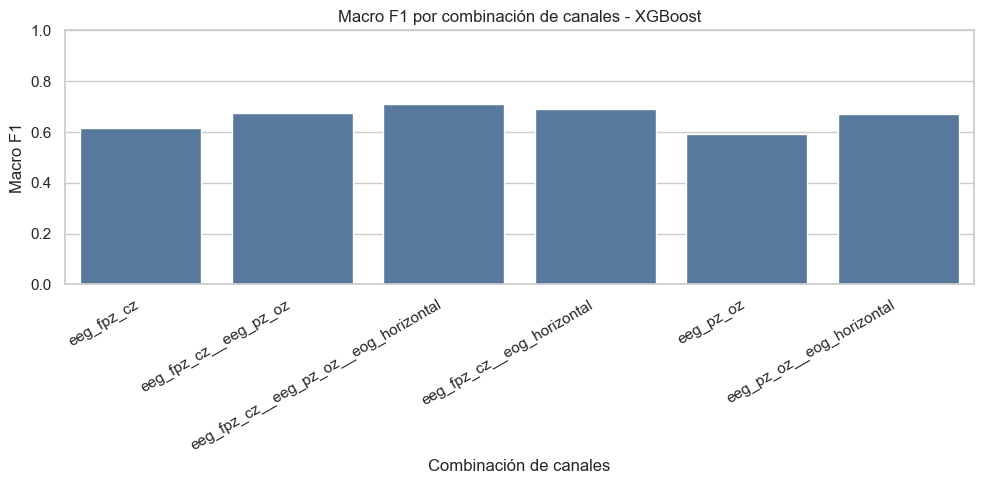

In [10]:
xgb_y_pred, xgb_metrics, xgb_per_class = evaluate_global("XGBoost", xgb_search)
xgb_test_eval_df, xgb_metrics_by_combo, xgb_per_class_by_combo = evaluate_by_combo("XGBoost", xgb_y_pred)

### Matriz de confusión global y por combinación

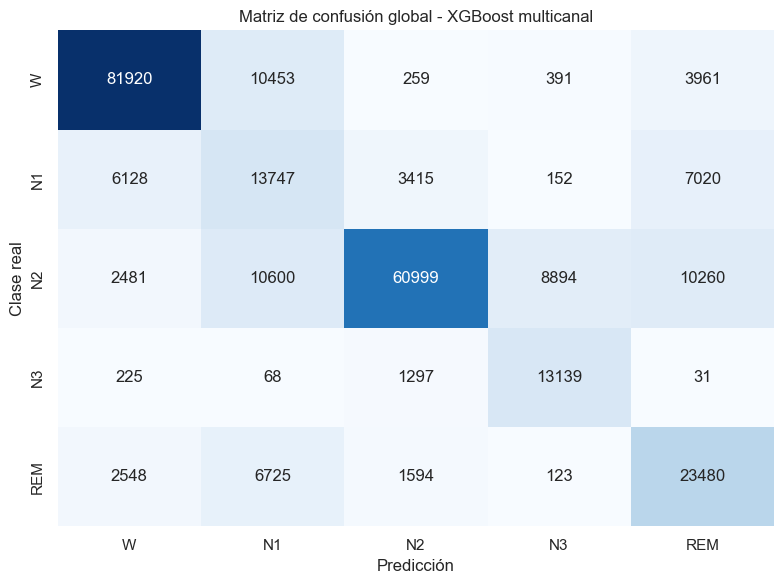

,W,N1,N2,N3,REM
W,81920,10453,259,391,3961
N1,6128,13747,3415,152,7020
N2,2481,10600,60999,8894,10260
N3,225,68,1297,13139,31
REM,2548,6725,1594,123,23480


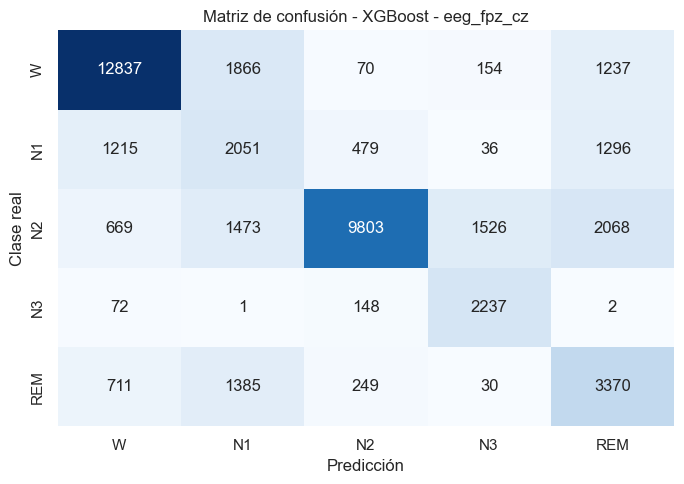

,W,N1,N2,N3,REM
W,12837,1866,70,154,1237
N1,1215,2051,479,36,1296
N2,669,1473,9803,1526,2068
N3,72,1,148,2237,2
REM,711,1385,249,30,3370


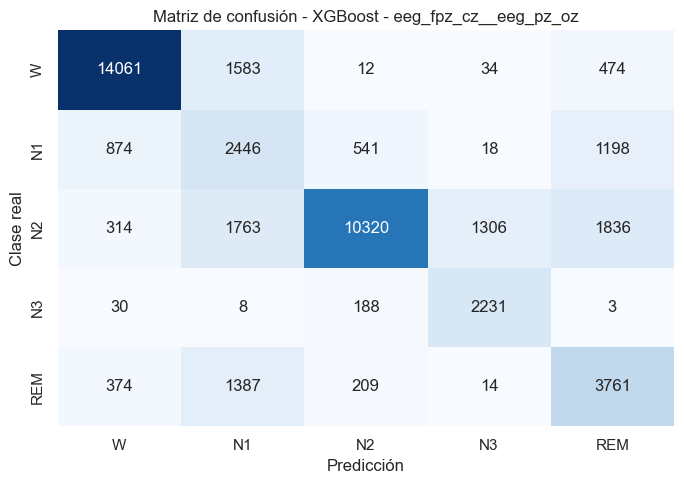

,W,N1,N2,N3,REM
W,14061,1583,12,34,474
N1,874,2446,541,18,1198
N2,314,1763,10320,1306,1836
N3,30,8,188,2231,3
REM,374,1387,209,14,3761


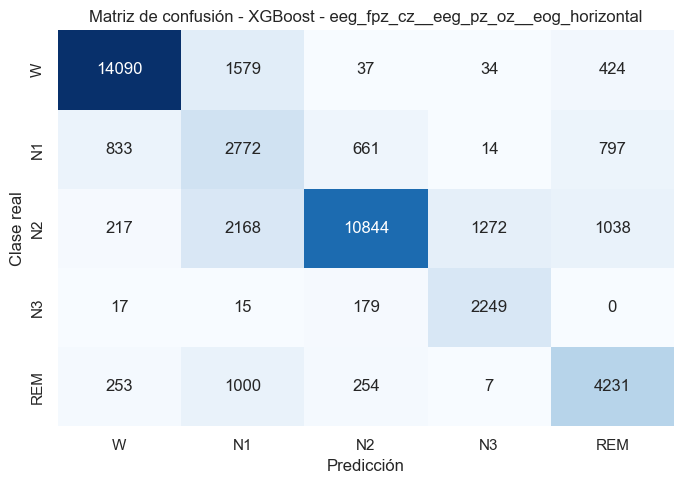

,W,N1,N2,N3,REM
W,14090,1579,37,34,424
N1,833,2772,661,14,797
N2,217,2168,10844,1272,1038
N3,17,15,179,2249,0
REM,253,1000,254,7,4231


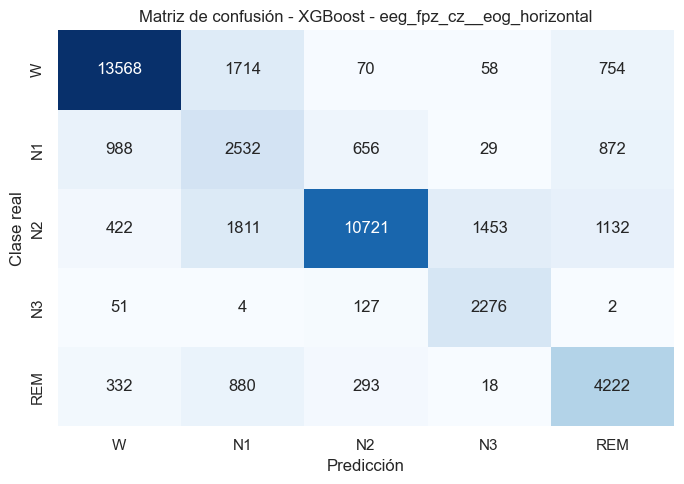

,W,N1,N2,N3,REM
W,13568,1714,70,58,754
N1,988,2532,656,29,872
N2,422,1811,10721,1453,1132
N3,51,4,127,2276,2
REM,332,880,293,18,4222


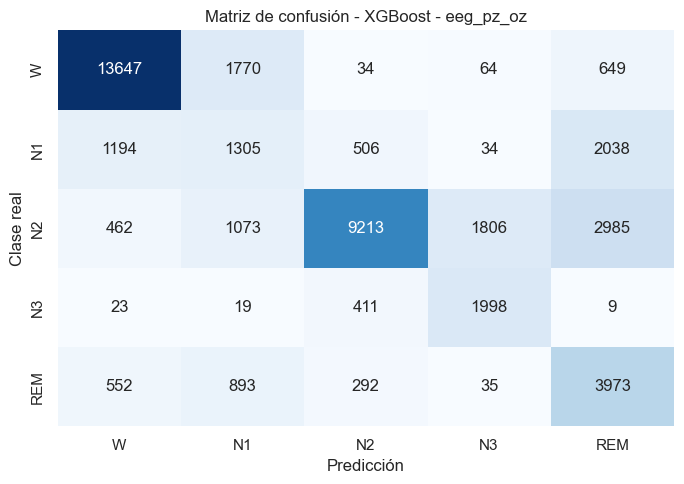

,W,N1,N2,N3,REM
W,13647,1770,34,64,649
N1,1194,1305,506,34,2038
N2,462,1073,9213,1806,2985
N3,23,19,411,1998,9
REM,552,893,292,35,3973


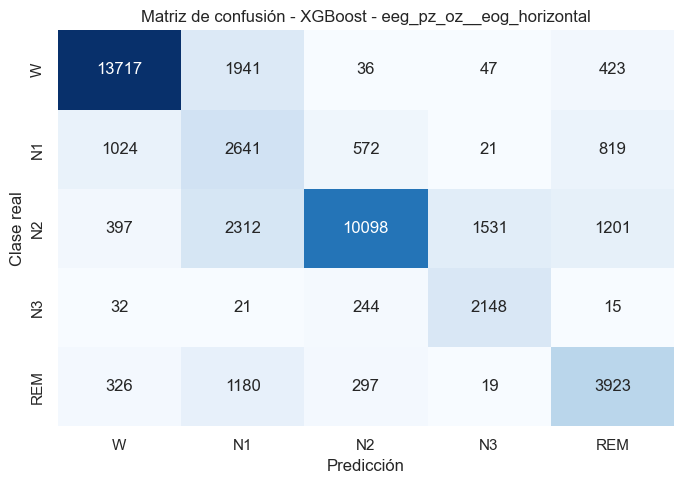

,W,N1,N2,N3,REM
W,13717,1941,36,47,423
N1,1024,2641,572,21,819
N2,397,2312,10098,1531,1201
N3,32,21,244,2148,15
REM,326,1180,297,19,3923


In [11]:
plot_confusion_matrices("XGBoost", xgb_test_eval_df)

### Importancia de variables y guardado de artefactos

In [12]:
train_df.columns

Index(['channel_combo', 'channel_count', 'split', 'epoch_idx_in_recording',
       'has_eeg_fpz_cz', 'has_eeg_pz_oz', 'has_eog_horizontal', 'recording_id',
       'subject_code', 'y', 'EEG_Fpz-Cz__alpha_power_abs',
       'EEG_Fpz-Cz__alpha_power_rel', 'EEG_Fpz-Cz__beta_power_abs',
       'EEG_Fpz-Cz__beta_power_rel', 'EEG_Fpz-Cz__delta_alpha_ratio',
       'EEG_Fpz-Cz__delta_power_abs', 'EEG_Fpz-Cz__delta_power_rel',
       'EEG_Fpz-Cz__sef95', 'EEG_Fpz-Cz__sigma_power_abs',
       'EEG_Fpz-Cz__sigma_power_rel', 'EEG_Fpz-Cz__spectral_entropy',
       'EEG_Fpz-Cz__theta_alpha_ratio', 'EEG_Fpz-Cz__theta_power_abs',
       'EEG_Fpz-Cz__theta_power_rel', 'EEG_Pz-Oz__alpha_power_abs',
       'EEG_Pz-Oz__alpha_power_rel', 'EEG_Pz-Oz__beta_power_abs',
       'EEG_Pz-Oz__beta_power_rel', 'EEG_Pz-Oz__delta_alpha_ratio',
       'EEG_Pz-Oz__delta_power_abs', 'EEG_Pz-Oz__delta_power_rel',
       'EEG_Pz-Oz__sef95', 'EEG_Pz-Oz__sigma_power_abs',
       'EEG_Pz-Oz__sigma_power_rel', 'EEG_Pz-Oz__spe

In [13]:
train_df[['channel_combo', 'channel_count', 'split', 'epoch_idx_in_recording',
       'has_eeg_fpz_cz', 'has_eeg_pz_oz', 'has_eog_horizontal', 'recording_id',
       'subject_code']].sample(10)

,channel_combo,channel_count,split,epoch_idx_in_recording,has_eeg_fpz_cz,has_eeg_pz_oz,has_eog_horizontal,recording_id,subject_code
209351,eeg_pz_oz__eog_horizontal,2,train,457,False,True,True,SC4221E0,22
682025,eeg_pz_oz__eog_horizontal,2,train,1125,False,True,True,SC4621E0,62
833925,eeg_pz_oz__eog_horizontal,2,train,765,False,True,True,SC4761E0,76
747982,eeg_pz_oz,1,train,663,False,True,False,SC4701E0,70
400398,eeg_fpz_cz__eeg_pz_oz__eog_horizontal,3,train,461,True,True,True,SC4382F0,38
106349,eeg_pz_oz,1,train,497,False,True,False,SC4102E0,10
263008,eeg_pz_oz,1,train,1004,False,True,False,SC4271F0,27
709545,eeg_pz_oz,1,train,526,False,True,False,SC4641E0,64
336074,eeg_fpz_cz__eog_horizontal,2,train,824,True,False,True,SC4331F0,33
179216,eeg_pz_oz__eog_horizontal,2,train,286,False,True,True,SC4162E0,16


In [14]:
X_train.head()

,EEG_Fpz-Cz__alpha_power_abs,EEG_Fpz-Cz__alpha_power_rel,EEG_Fpz-Cz__beta_power_abs,EEG_Fpz-Cz__beta_power_rel,EEG_Fpz-Cz__delta_alpha_ratio,EEG_Fpz-Cz__delta_power_abs,EEG_Fpz-Cz__delta_power_rel,EEG_Fpz-Cz__sef95,EEG_Fpz-Cz__sigma_power_abs,EEG_Fpz-Cz__sigma_power_rel,...,EEG_Pz-Oz__theta_alpha_ratio,EEG_Pz-Oz__theta_power_abs,EEG_Pz-Oz__theta_power_rel,EOG_horizontal__beta_power_abs,EOG_horizontal__delta_power_abs,EOG_horizontal__delta_power_rel,EOG_horizontal__hjorth_mobility,EOG_horizontal__kurtosis,EOG_horizontal__p2p_robust,EOG_horizontal__saccade_count
0,4.132619,0.010247,8.005553,0.019849,84.448240,348.99240,0.865313,6.25,3.506238,0.008694,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4.140185,0.007408,8.547596,0.015294,118.638700,491.18616,0.878890,5.25,1.985889,0.003553,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4.420617,0.005397,6.731600,0.008219,165.688390,732.44490,0.894271,4.75,2.095118,0.002558,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5.159684,0.008336,13.300922,0.021489,104.480900,539.08844,0.870950,6.00,3.834363,0.006195,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4.296539,0.008489,8.148181,0.016099,103.137566,443.13455,0.875535,5.75,2.656312,0.005248,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


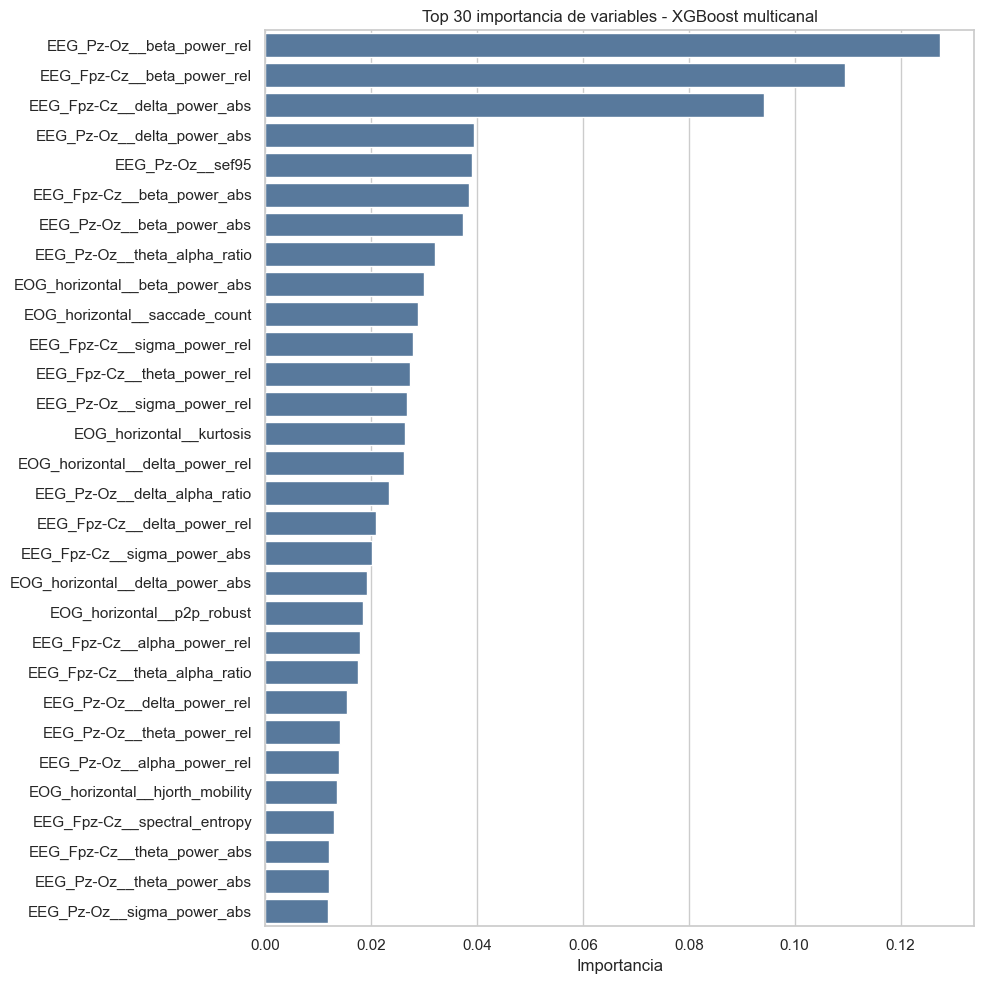

,feature,importance
17,EEG_Pz-Oz__beta_power_rel,0.127489
3,EEG_Fpz-Cz__beta_power_rel,0.109420
5,EEG_Fpz-Cz__delta_power_abs,0.094223
19,EEG_Pz-Oz__delta_power_abs,0.039390
21,EEG_Pz-Oz__sef95,0.039105
2,EEG_Fpz-Cz__beta_power_abs,0.038521
16,EEG_Pz-Oz__beta_power_abs,0.037352
25,EEG_Pz-Oz__theta_alpha_ratio,0.032094
28,EOG_horizontal__beta_power_abs,0.029903
34,EOG_horizontal__saccade_count,0.028930


In [15]:
xgb_feature_importance = plot_feature_importance("XGBoost", xgb_search.best_estimator_)

xgb_paths = save_artifacts(
    "XGBoost",
    "xgboost",
    xgb_search,
    xgb_metrics,
    xgb_metrics_by_combo,
    xgb_per_class_by_combo,
    xgb_feature_importance,
)

XGB_MODEL_PATH = MODEL_DIR / "best-xgboost-multicanal-model.json"
xgb_search.best_estimator_.get_booster().save_model(XGB_MODEL_PATH)

## Modelo 2: LightGBM

### Búsqueda de hiperparámetros

In [16]:
lgbm_model = LGBMClassifier(
    objective="multiclass",
    num_class=len(class_labels),
    subsample_freq=1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,
)

lgbm_param_distributions = {
    "n_estimators": [200, 300, 500, 700],
    "learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "num_leaves": [15, 31, 63, 127],
    "max_depth": [-1, 5, 8, 12],
    "min_child_samples": [20, 50, 100, 200],
    "reg_alpha": [0, 0.01, 0.1, 0.5],
    "reg_lambda": [0, 0.5, 1.0, 2.0],
}

lgbm_search = run_search("LightGBM", lgbm_model, lgbm_param_distributions)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END learning_rate=0.01, max_depth=-1, min_child_samples=200, n_estimators=300, num_leaves=31, reg_alpha=0.5, reg_lambda=0; total time= 3.0min
[CV] END learning_rate=0.01, max_depth=-1, min_child_samples=200, n_estimators=300, num_leaves=31, reg_alpha=0.5, reg_lambda=0; total time= 3.1min
[CV] END learning_rate=0.01, max_depth=-1, min_child_samples=200, n_estimators=300, num_leaves=31, reg_alpha=0.5, reg_lambda=0; total time= 3.1min
[CV] END learning_rate=0.01, max_depth=-1, min_child_samples=200, n_estimators=300, num_leaves=31, reg_alpha=0.5, reg_lambda=0; total time= 3.1min
[CV] END learning_rate=0.01, max_depth=-1, min_child_samples=200, n_estimators=300, num_leaves=31, reg_alpha=0.5, reg_lambda=0; total time= 3.1min
[CV] END learning_rate=0.03, max_depth=5, min_child_samples=50, n_estimators=200, num_leaves=15, reg_alpha=0.5, reg_lambda=1.0; total time= 1.1min
[CV] END learning_rate=0.03, max_depth=5, min_child_sampl

{'reg_lambda': 0,
 'reg_alpha': 0.01,
 'num_leaves': 31,
 'n_estimators': 200,
 'min_child_samples': 20,
 'max_depth': 12,
 'learning_rate': 0.05}

In [17]:
lgbm_cv_results = show_cv_results(lgbm_search)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,params
4,1,0.690714,0.015870,0.764428,0.003399,"{'reg_lambda': 0, 'reg_alpha': 0.01, 'num_leav..."
5,2,0.690403,0.014793,0.796605,0.003485,"{'reg_lambda': 0.5, 'reg_alpha': 0.1, 'num_lea..."
9,3,0.689513,0.016271,0.809117,0.003207,"{'reg_lambda': 2.0, 'reg_alpha': 0, 'num_leave..."
8,4,0.689382,0.016476,0.795374,0.002825,"{'reg_lambda': 2.0, 'reg_alpha': 0.01, 'num_le..."
7,5,0.687981,0.013234,0.739006,0.003870,"{'reg_lambda': 1.0, 'reg_alpha': 0.1, 'num_lea..."
1,6,0.683603,0.012253,0.728122,0.003890,"{'reg_lambda': 0, 'reg_alpha': 0.5, 'num_leave..."
6,7,0.682187,0.016614,0.861680,0.002666,"{'reg_lambda': 1.0, 'reg_alpha': 0, 'num_leave..."
2,8,0.681615,0.012709,0.723641,0.003873,"{'reg_lambda': 1.0, 'reg_alpha': 0.5, 'num_lea..."
3,9,0.680133,0.017834,0.891098,0.002367,"{'reg_lambda': 0, 'reg_alpha': 0.5, 'num_leave..."
0,10,0.671763,0.018527,0.926536,0.001960,"{'reg_lambda': 2.0, 'reg_alpha': 0, 'num_leave..."


### Evaluación global en test y por combinación de canales

=== LightGBM - evaluación global en test ===


accuracy                                                      0.711659
macro_f1                                                      0.654897
balanced_accuracy                                             0.701491
cohens_kappa                                                  0.613953
best_cv_macro_f1                                              0.690714
best_params          {'reg_lambda': 0, 'reg_alpha': 0.01, 'num_leav...
Name: value, dtype: object

,class,precision_per_class,recall_per_class,f1_per_class,support
0,W,0.872934,0.839613,0.855949,96984
1,N1,0.326935,0.450627,0.378942,30462
2,N2,0.904751,0.648572,0.755537,93234
3,N3,0.569892,0.893564,0.695934,14760
4,REM,0.521013,0.675080,0.588124,34470


              precision    recall  f1-score   support

           W       0.87      0.84      0.86     96984
          N1       0.33      0.45      0.38     30462
          N2       0.90      0.65      0.76     93234
          N3       0.57      0.89      0.70     14760
         REM       0.52      0.68      0.59     34470

    accuracy                           0.71    269910
   macro avg       0.64      0.70      0.65    269910
weighted avg       0.76      0.71      0.72    269910



,channel_combo,support,accuracy,macro_f1,balanced_accuracy,cohens_kappa
1,eeg_fpz_cz,44985,0.671068,0.613348,0.663559,0.561047
2,eeg_fpz_cz__eeg_pz_oz,44985,0.724686,0.667523,0.712038,0.630951
3,eeg_fpz_cz__eeg_pz_oz__eog_horizontal,44985,0.755341,0.707389,0.752010,0.671354
4,eeg_fpz_cz__eog_horizontal,44985,0.733111,0.682278,0.732274,0.642038
5,eeg_pz_oz,44985,0.665800,0.589907,0.636434,0.553558
6,eeg_pz_oz__eog_horizontal,44985,0.719951,0.670256,0.712633,0.625331
0,overall,269910,0.711659,0.654897,0.701491,0.613953


,channel_combo,class,precision_per_class,recall_per_class,f1_per_class,support
1,eeg_fpz_cz,N1,0.305462,0.394327,0.344252,5077
2,eeg_fpz_cz,N2,0.912726,0.627260,0.743535,15539
3,eeg_fpz_cz,N3,0.541757,0.915041,0.680574,2460
4,eeg_fpz_cz,REM,0.421525,0.589034,0.491396,5745
0,eeg_fpz_cz,W,0.822403,0.792131,0.806983,16164
6,eeg_fpz_cz__eeg_pz_oz,N1,0.333609,0.476069,0.392306,5077
7,eeg_fpz_cz__eeg_pz_oz,N2,0.913725,0.656349,0.763941,15539
8,eeg_fpz_cz__eeg_pz_oz,N3,0.600481,0.913415,0.724605,2460
9,eeg_fpz_cz__eeg_pz_oz,REM,0.519352,0.646997,0.576190,5745
5,eeg_fpz_cz__eeg_pz_oz,W,0.894190,0.867360,0.880570,16164


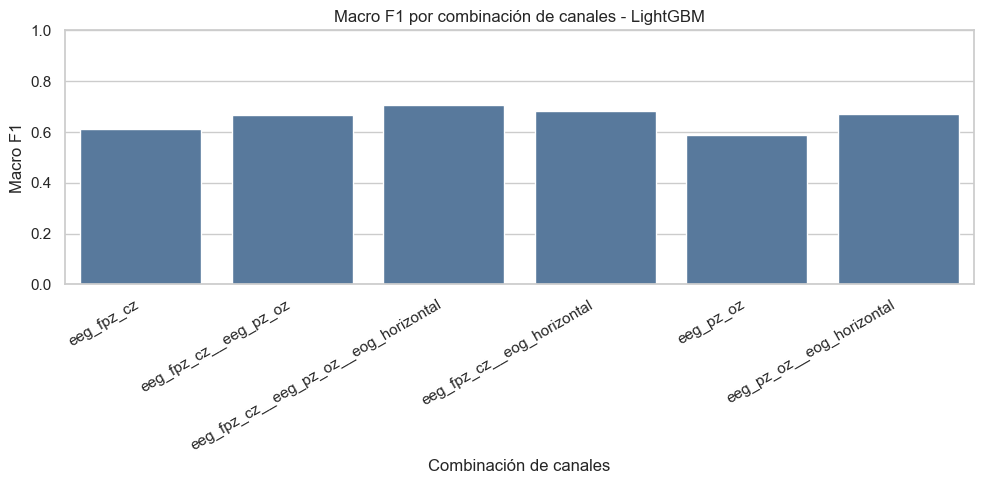

In [18]:
lgbm_y_pred, lgbm_metrics, lgbm_per_class = evaluate_global("LightGBM", lgbm_search)
lgbm_test_eval_df, lgbm_metrics_by_combo, lgbm_per_class_by_combo = evaluate_by_combo("LightGBM", lgbm_y_pred)

### Matriz de confusión global y por combinación

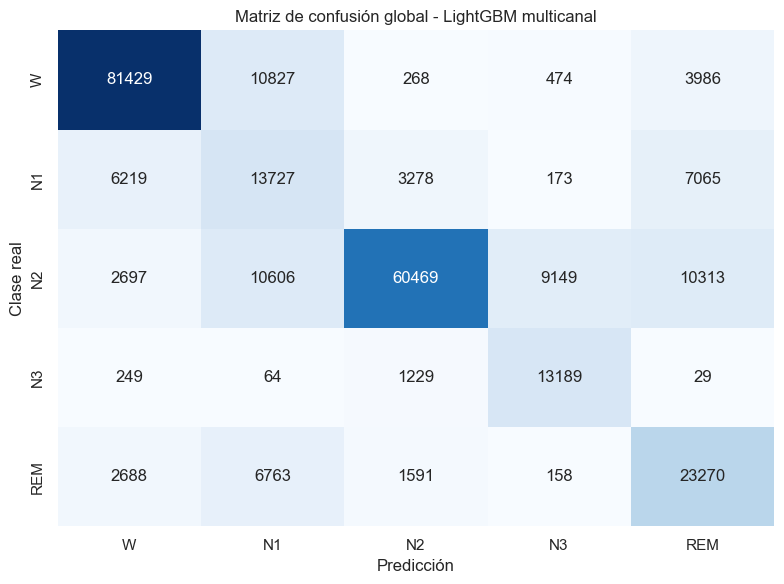

,W,N1,N2,N3,REM
W,81429,10827,268,474,3986
N1,6219,13727,3278,173,7065
N2,2697,10606,60469,9149,10313
N3,249,64,1229,13189,29
REM,2688,6763,1591,158,23270


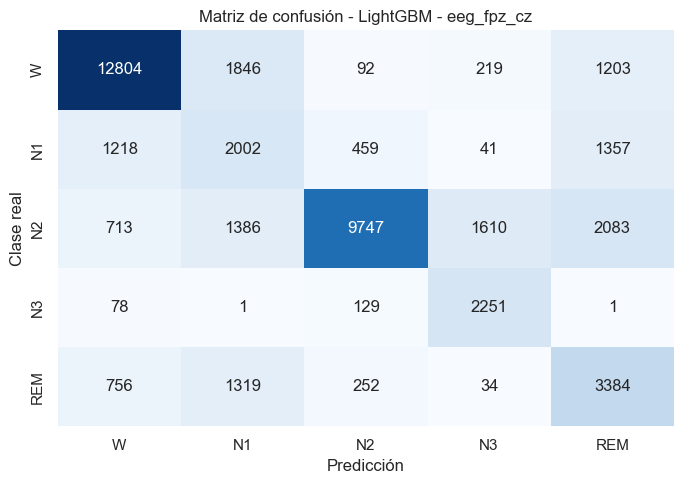

,W,N1,N2,N3,REM
W,12804,1846,92,219,1203
N1,1218,2002,459,41,1357
N2,713,1386,9747,1610,2083
N3,78,1,129,2251,1
REM,756,1319,252,34,3384


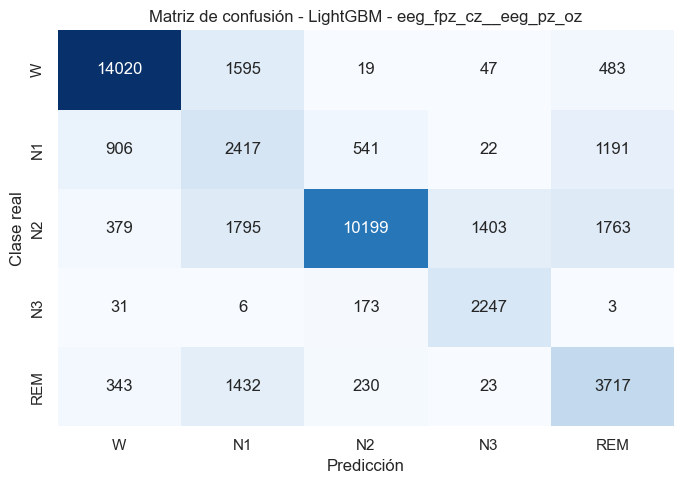

,W,N1,N2,N3,REM
W,14020,1595,19,47,483
N1,906,2417,541,22,1191
N2,379,1795,10199,1403,1763
N3,31,6,173,2247,3
REM,343,1432,230,23,3717


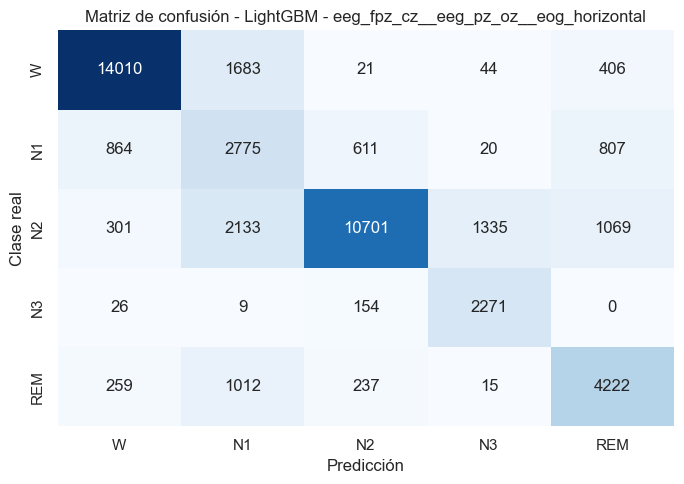

,W,N1,N2,N3,REM
W,14010,1683,21,44,406
N1,864,2775,611,20,807
N2,301,2133,10701,1335,1069
N3,26,9,154,2271,0
REM,259,1012,237,15,4222


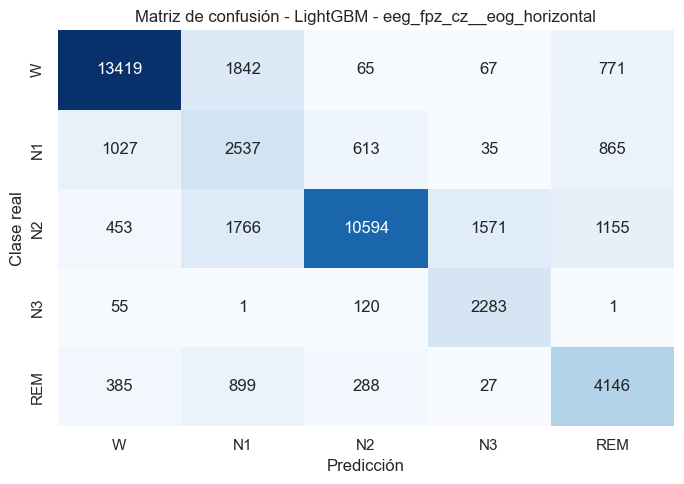

,W,N1,N2,N3,REM
W,13419,1842,65,67,771
N1,1027,2537,613,35,865
N2,453,1766,10594,1571,1155
N3,55,1,120,2283,1
REM,385,899,288,27,4146


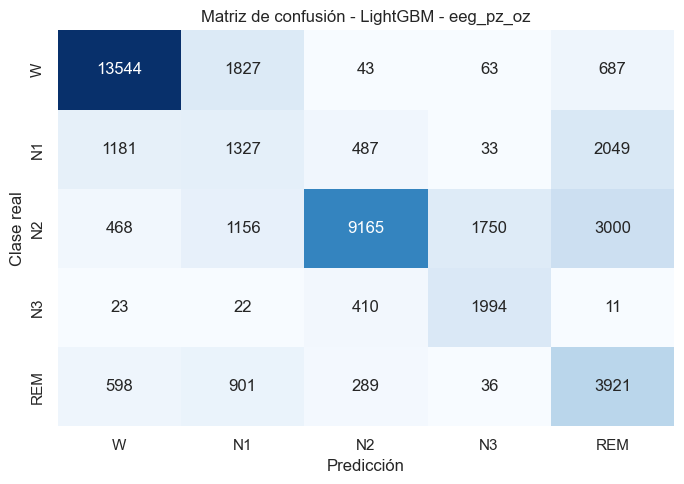

,W,N1,N2,N3,REM
W,13544,1827,43,63,687
N1,1181,1327,487,33,2049
N2,468,1156,9165,1750,3000
N3,23,22,410,1994,11
REM,598,901,289,36,3921


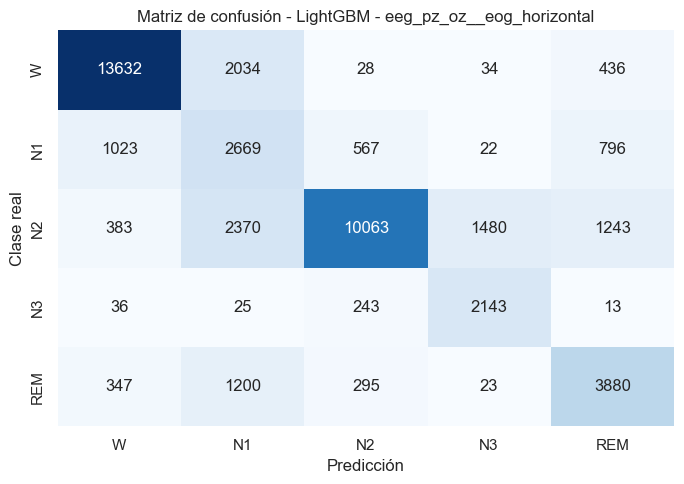

,W,N1,N2,N3,REM
W,13632,2034,28,34,436
N1,1023,2669,567,22,796
N2,383,2370,10063,1480,1243
N3,36,25,243,2143,13
REM,347,1200,295,23,3880


In [19]:
plot_confusion_matrices("LightGBM", lgbm_test_eval_df)

### Importancia de variables y guardado de artefactos

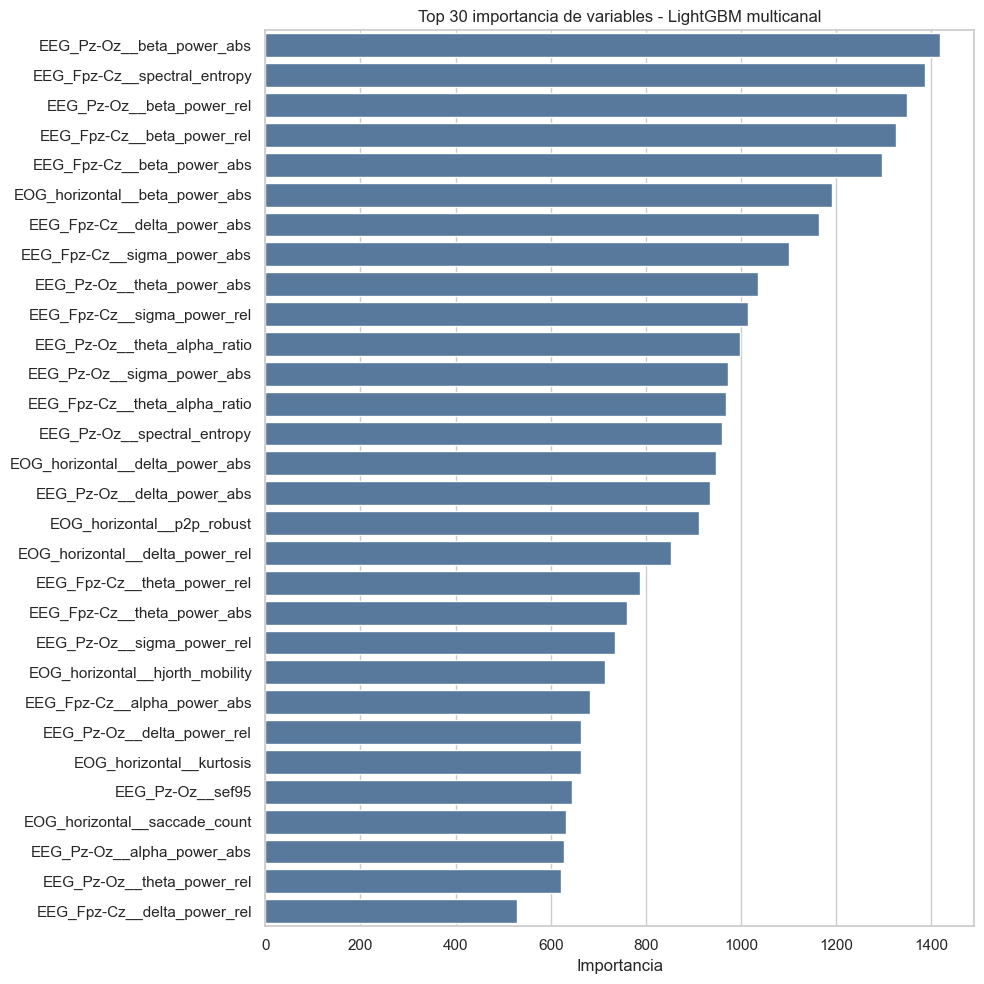

,feature,importance
16,EEG_Pz-Oz__beta_power_abs,1419
10,EEG_Fpz-Cz__spectral_entropy,1387
17,EEG_Pz-Oz__beta_power_rel,1349
3,EEG_Fpz-Cz__beta_power_rel,1326
2,EEG_Fpz-Cz__beta_power_abs,1297
28,EOG_horizontal__beta_power_abs,1192
5,EEG_Fpz-Cz__delta_power_abs,1165
8,EEG_Fpz-Cz__sigma_power_abs,1102
26,EEG_Pz-Oz__theta_power_abs,1036
9,EEG_Fpz-Cz__sigma_power_rel,1015


In [20]:
lgbm_feature_importance = plot_feature_importance("LightGBM", lgbm_search.best_estimator_)

lgbm_paths = save_artifacts(
    "LightGBM",
    "lightgbm",
    lgbm_search,
    lgbm_metrics,
    lgbm_metrics_by_combo,
    lgbm_per_class_by_combo,
    lgbm_feature_importance,
)

## Modelo 3: Random Forest

Ensamble de árboles por bagging. Se exploran número de árboles, profundidad, tamaños mínimos de división/hoja, número de variables por división y fracción de muestras por árbol.

### Búsqueda de hiperparámetros

In [21]:
rf_model = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

rf_param_distributions = {
    "n_estimators": [100, 200],
    "max_depth": [10, 15, 20, 25],
    "min_samples_split": [10, 50, 100],
    "min_samples_leaf": [5, 20, 50],
    "max_features": ["sqrt", "log2"],
    "max_samples": [0.1, 0.2, 0.3],
}

rf_search = run_search("Random Forest", rf_model, rf_param_distributions)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END max_depth=25, max_features=log2, max_samples=0.3, min_samples_leaf=20, min_samples_split=100, n_estimators=100; total time= 2.8min
[CV] END max_depth=25, max_features=log2, max_samples=0.3, min_samples_leaf=20, min_samples_split=100, n_estimators=100; total time= 2.8min
[CV] END max_depth=25, max_features=log2, max_samples=0.3, min_samples_leaf=20, min_samples_split=100, n_estimators=100; total time= 2.8min
[CV] END max_depth=25, max_features=log2, max_samples=0.3, min_samples_leaf=20, min_samples_split=100, n_estimators=100; total time= 2.8min
[CV] END max_depth=25, max_features=log2, max_samples=0.3, min_samples_leaf=20, min_samples_split=100, n_estimators=100; total time= 2.8min
[CV] END max_depth=10, max_features=log2, max_samples=0.2, min_samples_leaf=5, min_samples_split=50, n_estimators=200; total time= 2.9min
[CV] END max_depth=10, max_features=log2, max_samples=0.2, min_samples_leaf=5, min_samples_split=50, 

{'n_estimators': 100,
 'min_samples_split': 100,
 'min_samples_leaf': 20,
 'max_samples': 0.3,
 'max_features': 'log2',
 'max_depth': 25}

In [22]:
rf_cv_results = show_cv_results(rf_search)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,params
0,1,0.682119,0.014251,0.768417,0.002753,"{'n_estimators': 100, 'min_samples_split': 100..."
6,2,0.682087,0.015956,0.851868,0.002318,"{'n_estimators': 100, 'min_samples_split': 10,..."
5,3,0.681078,0.013950,0.742113,0.003140,"{'n_estimators': 200, 'min_samples_split': 100..."
2,4,0.681065,0.014584,0.763769,0.003115,"{'n_estimators': 100, 'min_samples_split': 10,..."
9,5,0.679628,0.013625,0.746023,0.003416,"{'n_estimators': 100, 'min_samples_split': 100..."
7,6,0.678907,0.014153,0.742580,0.002857,"{'n_estimators': 100, 'min_samples_split': 100..."
8,7,0.677708,0.013675,0.731095,0.003339,"{'n_estimators': 200, 'min_samples_split': 50,..."
4,8,0.677204,0.012584,0.728516,0.003119,"{'n_estimators': 100, 'min_samples_split': 50,..."
1,9,0.663520,0.012802,0.706300,0.003742,"{'n_estimators': 200, 'min_samples_split': 50,..."
3,10,0.662111,0.013813,0.701872,0.003027,"{'n_estimators': 100, 'min_samples_split': 10,..."


### Evaluación global en test y por combinación de canales

=== Random Forest - evaluación global en test ===


accuracy                                                      0.706247
macro_f1                                                       0.65026
balanced_accuracy                                             0.695895
cohens_kappa                                                  0.606661
best_cv_macro_f1                                              0.682119
best_params          {'n_estimators': 100, 'min_samples_split': 100...
Name: value, dtype: object

,class,precision_per_class,recall_per_class,f1_per_class,support
0,W,0.864671,0.835633,0.849904,96984
1,N1,0.320137,0.449150,0.373825,30462
2,N2,0.900298,0.642030,0.749540,93234
3,N3,0.567915,0.886924,0.692444,14760
4,REM,0.522662,0.665738,0.585587,34470


              precision    recall  f1-score   support

           W       0.86      0.84      0.85     96984
          N1       0.32      0.45      0.37     30462
          N2       0.90      0.64      0.75     93234
          N3       0.57      0.89      0.69     14760
         REM       0.52      0.67      0.59     34470

    accuracy                           0.71    269910
   macro avg       0.64      0.70      0.65    269910
weighted avg       0.76      0.71      0.72    269910



,channel_combo,support,accuracy,macro_f1,balanced_accuracy,cohens_kappa
1,eeg_fpz_cz,44985,0.656508,0.600477,0.655852,0.543813
2,eeg_fpz_cz__eeg_pz_oz,44985,0.722396,0.664550,0.708615,0.626811
3,eeg_fpz_cz__eeg_pz_oz__eog_horizontal,44985,0.747449,0.699972,0.742216,0.660221
4,eeg_fpz_cz__eog_horizontal,44985,0.725197,0.676650,0.723441,0.631300
5,eeg_pz_oz,44985,0.670423,0.597709,0.642464,0.559975
6,eeg_pz_oz__eog_horizontal,44985,0.715505,0.666375,0.702781,0.618886
0,overall,269910,0.706247,0.650260,0.695895,0.606661


,channel_combo,class,precision_per_class,recall_per_class,f1_per_class,support
1,eeg_fpz_cz,N1,0.299501,0.402206,0.343338,5077
2,eeg_fpz_cz,N2,0.904351,0.620632,0.736099,15539
3,eeg_fpz_cz,N3,0.500560,0.908537,0.645487,2460
4,eeg_fpz_cz,REM,0.423455,0.592689,0.493979,5745
0,eeg_fpz_cz,W,0.813963,0.755197,0.783479,16164
6,eeg_fpz_cz__eeg_pz_oz,N1,0.341316,0.435099,0.382544,5077
7,eeg_fpz_cz__eeg_pz_oz,N2,0.907509,0.657957,0.762843,15539
8,eeg_fpz_cz__eeg_pz_oz,N3,0.610138,0.919919,0.733668,2460
9,eeg_fpz_cz__eeg_pz_oz,REM,0.502829,0.665274,0.572756,5745
5,eeg_fpz_cz__eeg_pz_oz,W,0.877141,0.864823,0.870939,16164


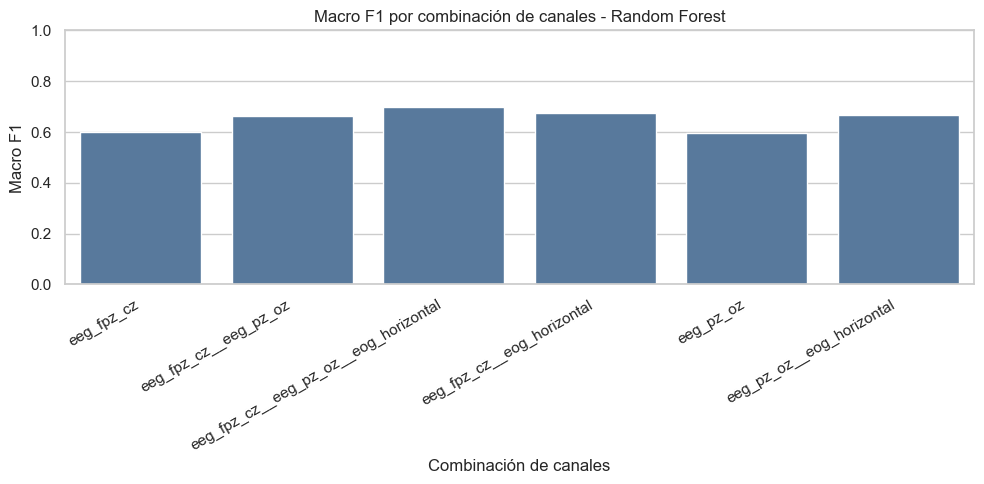

In [23]:
rf_y_pred, rf_metrics, rf_per_class = evaluate_global("Random Forest", rf_search)
rf_test_eval_df, rf_metrics_by_combo, rf_per_class_by_combo = evaluate_by_combo("Random Forest", rf_y_pred)

### Matriz de confusión global y por combinación

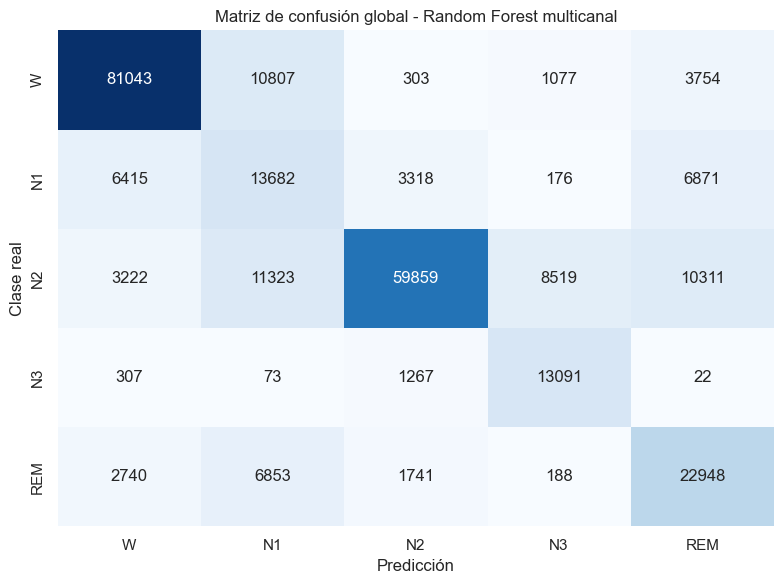

,W,N1,N2,N3,REM
W,81043,10807,303,1077,3754
N1,6415,13682,3318,176,6871
N2,3222,11323,59859,8519,10311
N3,307,73,1267,13091,22
REM,2740,6853,1741,188,22948


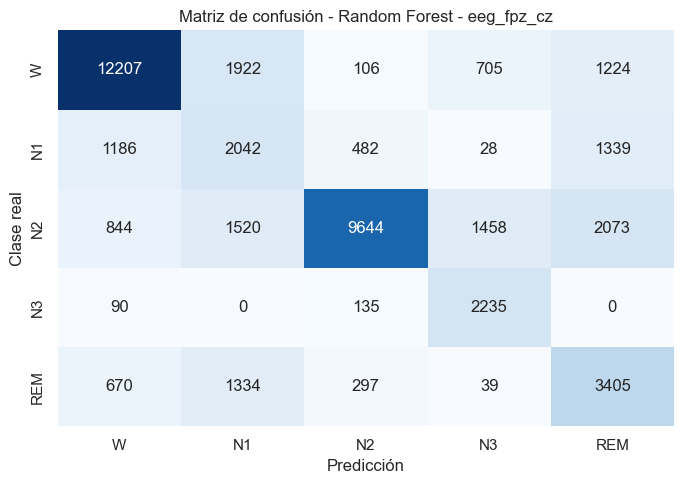

,W,N1,N2,N3,REM
W,12207,1922,106,705,1224
N1,1186,2042,482,28,1339
N2,844,1520,9644,1458,2073
N3,90,0,135,2235,0
REM,670,1334,297,39,3405


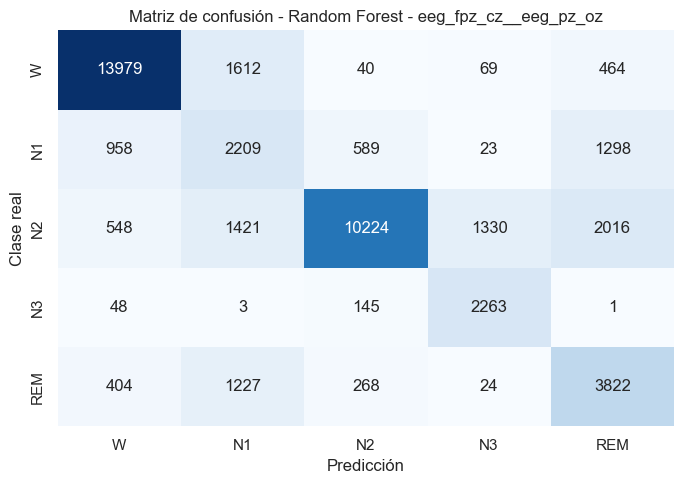

,W,N1,N2,N3,REM
W,13979,1612,40,69,464
N1,958,2209,589,23,1298
N2,548,1421,10224,1330,2016
N3,48,3,145,2263,1
REM,404,1227,268,24,3822


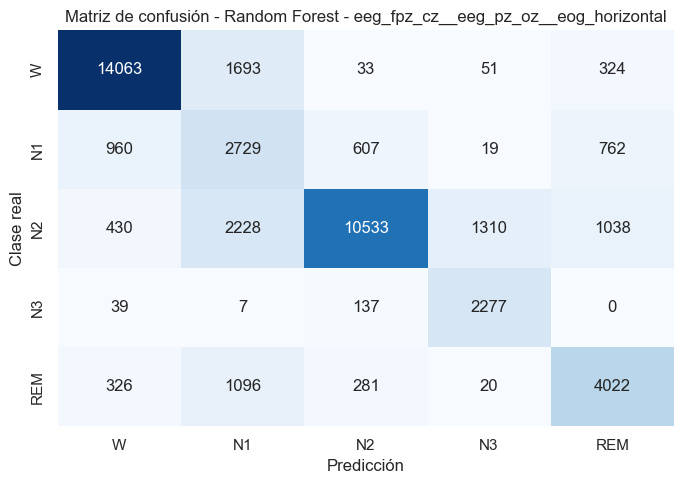

,W,N1,N2,N3,REM
W,14063,1693,33,51,324
N1,960,2729,607,19,762
N2,430,2228,10533,1310,1038
N3,39,7,137,2277,0
REM,326,1096,281,20,4022


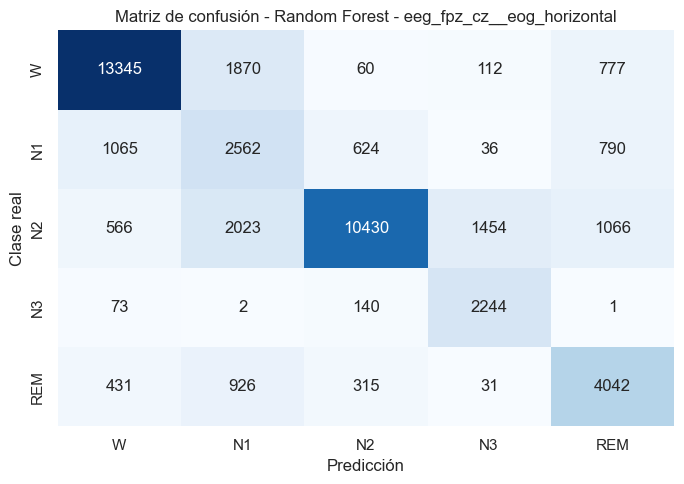

,W,N1,N2,N3,REM
W,13345,1870,60,112,777
N1,1065,2562,624,36,790
N2,566,2023,10430,1454,1066
N3,73,2,140,2244,1
REM,431,926,315,31,4042


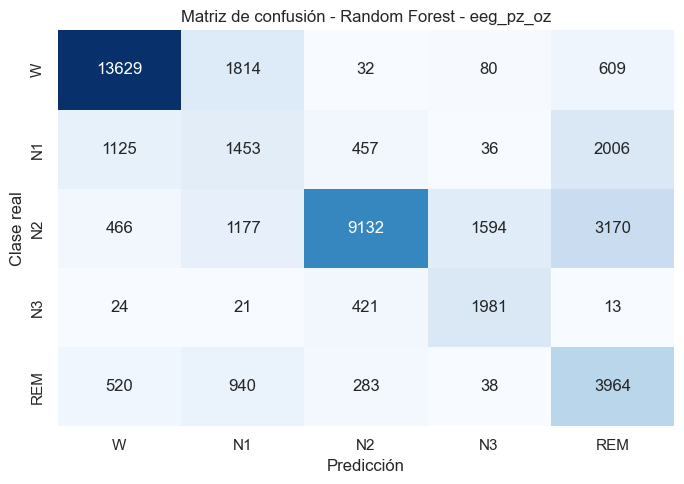

,W,N1,N2,N3,REM
W,13629,1814,32,80,609
N1,1125,1453,457,36,2006
N2,466,1177,9132,1594,3170
N3,24,21,421,1981,13
REM,520,940,283,38,3964


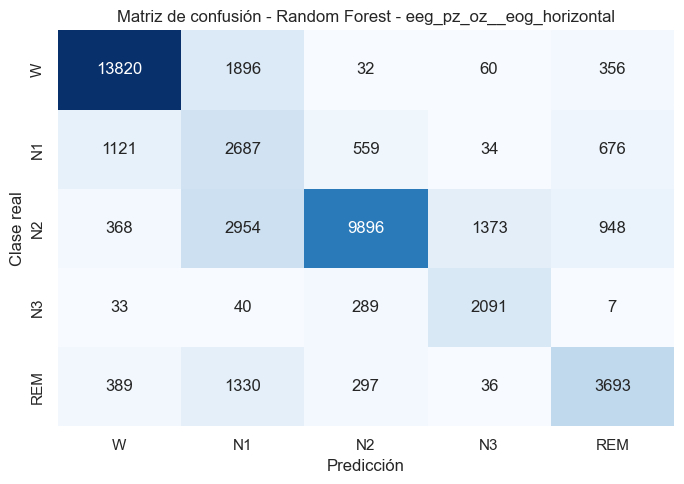

,W,N1,N2,N3,REM
W,13820,1896,32,60,356
N1,1121,2687,559,34,676
N2,368,2954,9896,1373,948
N3,33,40,289,2091,7
REM,389,1330,297,36,3693


In [24]:
plot_confusion_matrices("Random Forest", rf_test_eval_df)

### Importancia de variables y guardado de artefactos

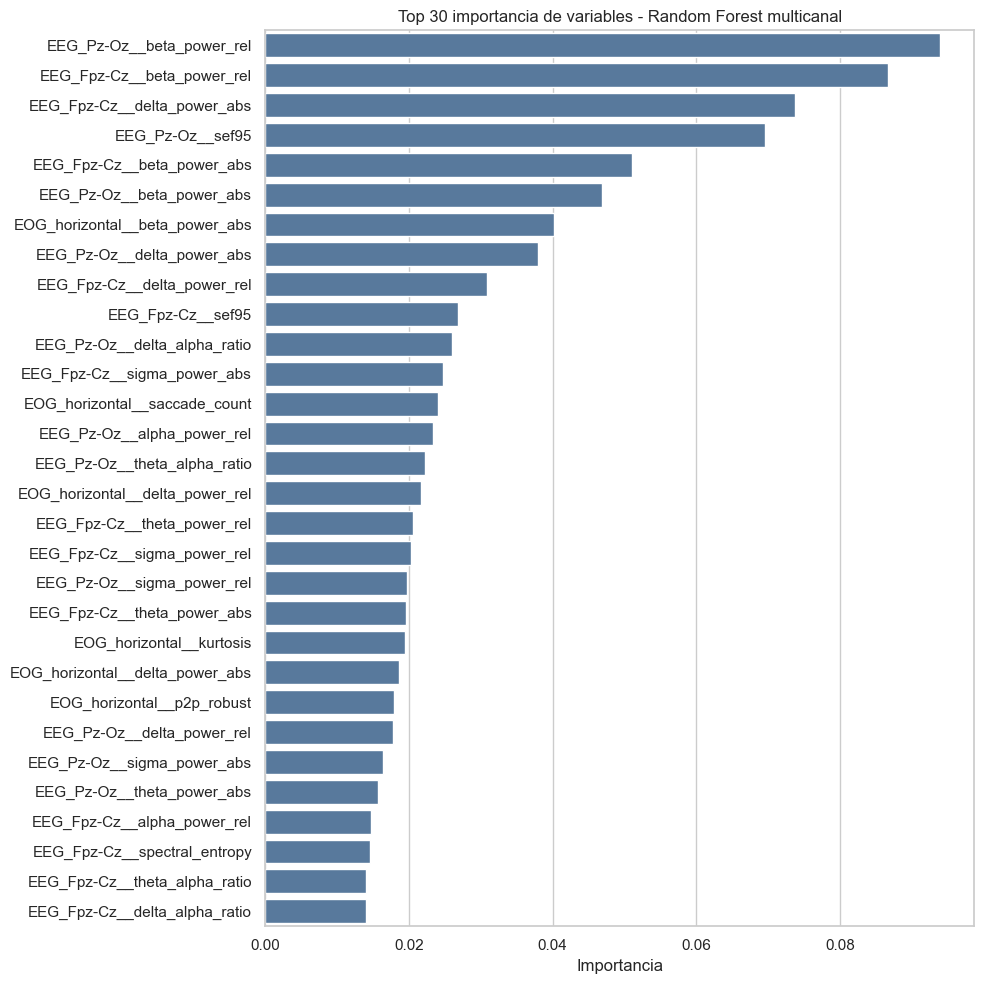

,feature,importance
17,EEG_Pz-Oz__beta_power_rel,0.093978
3,EEG_Fpz-Cz__beta_power_rel,0.086632
5,EEG_Fpz-Cz__delta_power_abs,0.073744
21,EEG_Pz-Oz__sef95,0.069562
2,EEG_Fpz-Cz__beta_power_abs,0.051004
16,EEG_Pz-Oz__beta_power_abs,0.046852
28,EOG_horizontal__beta_power_abs,0.040195
19,EEG_Pz-Oz__delta_power_abs,0.037959
6,EEG_Fpz-Cz__delta_power_rel,0.030925
7,EEG_Fpz-Cz__sef95,0.026803


In [25]:
rf_feature_importance = plot_feature_importance("Random Forest", rf_search.best_estimator_)

rf_paths = save_artifacts(
    "Random Forest",
    "random-forest",
    rf_search,
    rf_metrics,
    rf_metrics_by_combo,
    rf_per_class_by_combo,
    rf_feature_importance,
)

## Modelo 4: Árbol de Decisión

Modelo base interpretable de un solo árbol. Se exploran criterio de división, profundidad, tamaños mínimos de división/hoja y número de variables por división.

### Búsqueda de hiperparámetros

In [26]:
dt_model = DecisionTreeClassifier(
    random_state=RANDOM_STATE,
)

dt_param_distributions = {
    "criterion": ["gini", "entropy"],
    "max_depth": [5, 8, 10, 15, 20, None],
    "min_samples_split": [2, 10, 50, 100],
    "min_samples_leaf": [1, 5, 20, 50, 100],
    "max_features": [None, "sqrt", 0.5],
}

dt_search = run_search("Decision Tree", dt_model, dt_param_distributions)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END criterion=gini, max_depth=20, max_features=0.5, min_samples_leaf=20, min_samples_split=50; total time=  17.2s
[CV] END criterion=gini, max_depth=20, max_features=0.5, min_samples_leaf=20, min_samples_split=50; total time=  17.5s
[CV] END criterion=gini, max_depth=20, max_features=0.5, min_samples_leaf=20, min_samples_split=50; total time=  17.5s
[CV] END criterion=gini, max_depth=20, max_features=0.5, min_samples_leaf=20, min_samples_split=50; total time=  17.7s
[CV] END criterion=gini, max_depth=20, max_features=0.5, min_samples_leaf=20, min_samples_split=50; total time=  17.2s
[CV] END criterion=gini, max_depth=None, max_features=0.5, min_samples_leaf=1, min_samples_split=2; total time=  21.5s
[CV] END criterion=gini, max_depth=None, max_features=0.5, min_samples_leaf=1, min_samples_split=2; total time=  22.1s
[CV] END criterion=gini, max_depth=None, max_features=0.5, min_samples_leaf=1, min_samples_split=2; total 

{'min_samples_split': 2,
 'min_samples_leaf': 50,
 'max_features': 0.5,
 'max_depth': 20,
 'criterion': 'gini'}

In [27]:
dt_cv_results = show_cv_results(dt_search)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,params
8,1,0.640419,0.015838,0.752652,0.002582,"{'min_samples_split': 2, 'min_samples_leaf': 5..."
3,2,0.638896,0.013842,0.709536,0.005559,"{'min_samples_split': 50, 'min_samples_leaf': ..."
1,3,0.633659,0.016313,0.776354,0.002631,"{'min_samples_split': 50, 'min_samples_leaf': ..."
7,4,0.586696,0.022483,0.632713,0.008312,"{'min_samples_split': 10, 'min_samples_leaf': ..."
6,5,0.579430,0.022684,0.603206,0.010980,"{'min_samples_split': 100, 'min_samples_leaf':..."
5,6,0.579355,0.022710,0.603537,0.010939,"{'min_samples_split': 10, 'min_samples_leaf': ..."
0,7,0.551379,0.020836,1.000000,0.000000,"{'min_samples_split': 2, 'min_samples_leaf': 1..."
4,8,0.546399,0.013482,0.581109,0.016813,"{'min_samples_split': 10, 'min_samples_leaf': ..."
2,9,0.489259,0.026727,0.505458,0.009975,"{'min_samples_split': 50, 'min_samples_leaf': ..."
9,10,0.460198,0.014101,0.470020,0.009919,"{'min_samples_split': 50, 'min_samples_leaf': ..."


### Evaluación global en test y por combinación de canales

=== Decision Tree - evaluación global en test ===


accuracy                                                      0.650569
macro_f1                                                      0.600139
balanced_accuracy                                             0.651689
cohens_kappa                                                   0.53979
best_cv_macro_f1                                              0.640419
best_params          {'min_samples_split': 2, 'min_samples_leaf': 5...
Name: value, dtype: object

,class,precision_per_class,recall_per_class,f1_per_class,support
0,W,0.865461,0.789305,0.825631,96984
1,N1,0.272196,0.443044,0.337215,30462
2,N2,0.889096,0.547043,0.677335,93234
3,N3,0.517141,0.833943,0.638400,14760
4,REM,0.438504,0.645112,0.522112,34470


              precision    recall  f1-score   support

           W       0.87      0.79      0.83     96984
          N1       0.27      0.44      0.34     30462
          N2       0.89      0.55      0.68     93234
          N3       0.52      0.83      0.64     14760
         REM       0.44      0.65      0.52     34470

    accuracy                           0.65    269910
   macro avg       0.60      0.65      0.60    269910
weighted avg       0.73      0.65      0.67    269910



,channel_combo,support,accuracy,macro_f1,balanced_accuracy,cohens_kappa
1,eeg_fpz_cz,44985,0.613627,0.570095,0.629850,0.496313
2,eeg_fpz_cz__eeg_pz_oz,44985,0.664199,0.609193,0.657688,0.555225
3,eeg_fpz_cz__eeg_pz_oz__eog_horizontal,44985,0.690675,0.641078,0.688818,0.588919
4,eeg_fpz_cz__eog_horizontal,44985,0.666889,0.627340,0.680185,0.561522
5,eeg_pz_oz,44985,0.607647,0.539782,0.594329,0.486020
6,eeg_pz_oz__eog_horizontal,44985,0.660376,0.611214,0.659267,0.552013
0,overall,269910,0.650569,0.600139,0.651689,0.539790


,channel_combo,class,precision_per_class,recall_per_class,f1_per_class,support
1,eeg_fpz_cz,N1,0.254613,0.429387,0.319672,5077
2,eeg_fpz_cz,N2,0.895822,0.542313,0.675619,15539
3,eeg_fpz_cz,N3,0.481822,0.872764,0.620879,2460
4,eeg_fpz_cz,REM,0.381655,0.598956,0.466229,5745
0,eeg_fpz_cz,W,0.842366,0.705828,0.768076,16164
6,eeg_fpz_cz__eeg_pz_oz,N1,0.278213,0.482175,0.352839,5077
7,eeg_fpz_cz__eeg_pz_oz,N2,0.892427,0.568055,0.694219,15539
8,eeg_fpz_cz__eeg_pz_oz,N3,0.532058,0.870325,0.660395,2460
9,eeg_fpz_cz__eeg_pz_oz,REM,0.447864,0.542037,0.490471,5745
5,eeg_fpz_cz__eeg_pz_oz,W,0.871458,0.825848,0.848040,16164


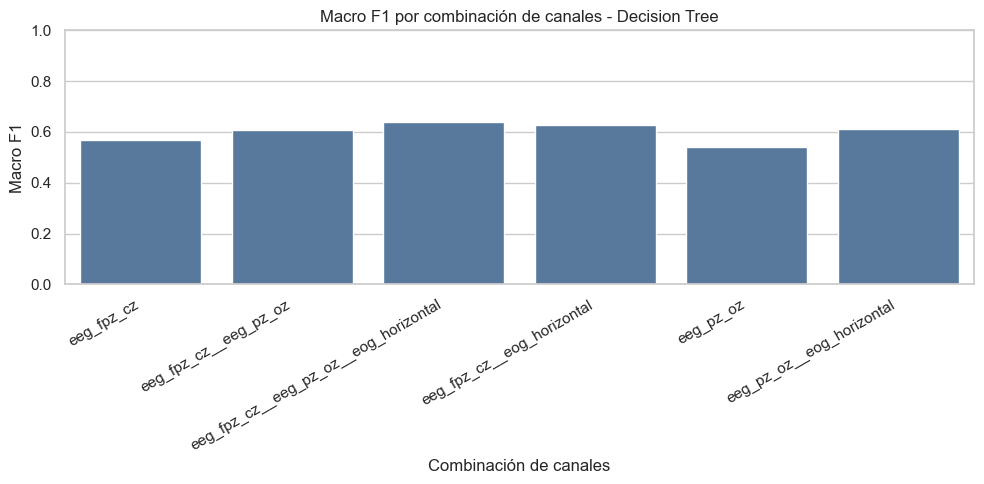

In [28]:
dt_y_pred, dt_metrics, dt_per_class = evaluate_global("Decision Tree", dt_search)
dt_test_eval_df, dt_metrics_by_combo, dt_per_class_by_combo = evaluate_by_combo("Decision Tree", dt_y_pred)

### Matriz de confusión global y por combinación

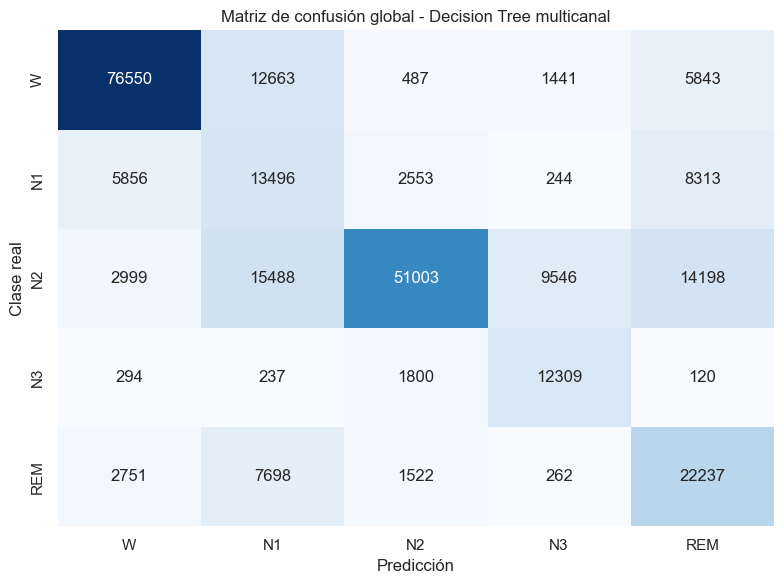

,W,N1,N2,N3,REM
W,76550,12663,487,1441,5843
N1,5856,13496,2553,244,8313
N2,2999,15488,51003,9546,14198
N3,294,237,1800,12309,120
REM,2751,7698,1522,262,22237


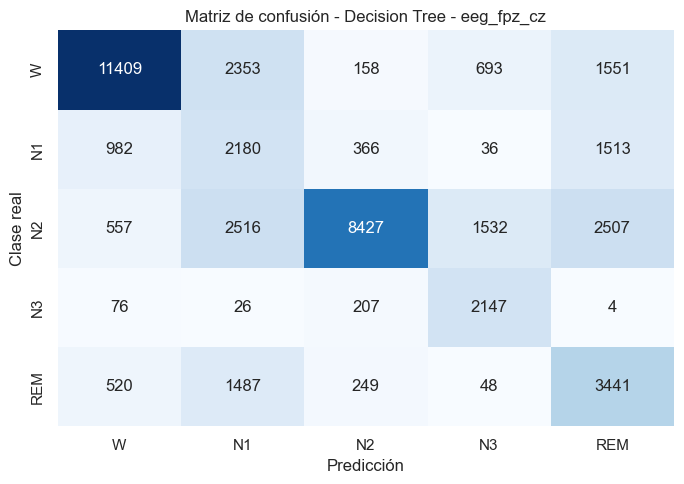

,W,N1,N2,N3,REM
W,11409,2353,158,693,1551
N1,982,2180,366,36,1513
N2,557,2516,8427,1532,2507
N3,76,26,207,2147,4
REM,520,1487,249,48,3441


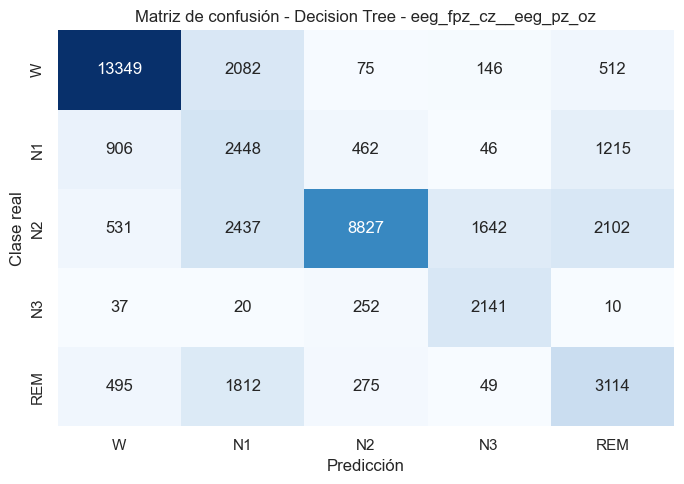

,W,N1,N2,N3,REM
W,13349,2082,75,146,512
N1,906,2448,462,46,1215
N2,531,2437,8827,1642,2102
N3,37,20,252,2141,10
REM,495,1812,275,49,3114


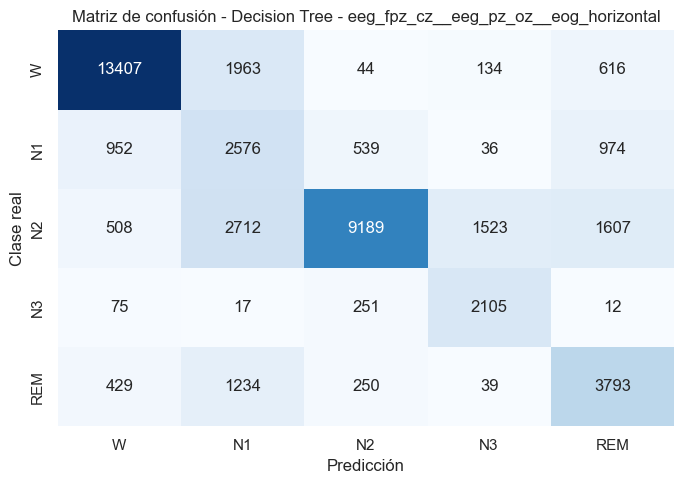

,W,N1,N2,N3,REM
W,13407,1963,44,134,616
N1,952,2576,539,36,974
N2,508,2712,9189,1523,1607
N3,75,17,251,2105,12
REM,429,1234,250,39,3793


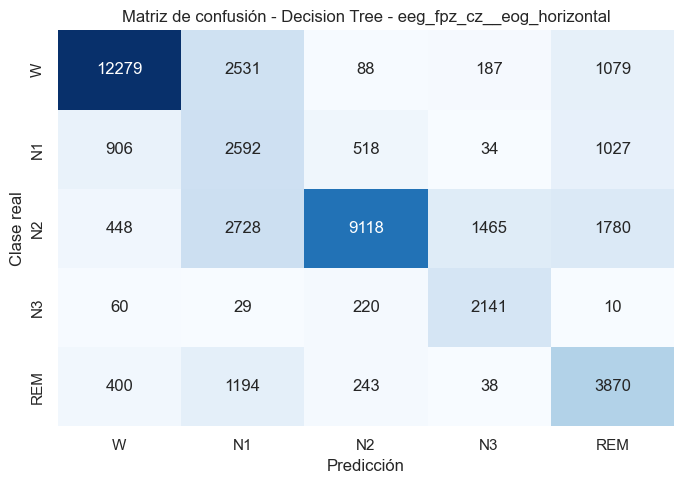

,W,N1,N2,N3,REM
W,12279,2531,88,187,1079
N1,906,2592,518,34,1027
N2,448,2728,9118,1465,1780
N3,60,29,220,2141,10
REM,400,1194,243,38,3870


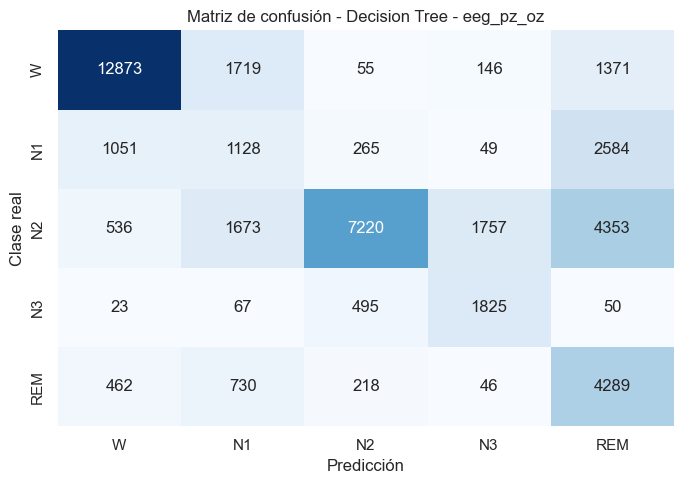

,W,N1,N2,N3,REM
W,12873,1719,55,146,1371
N1,1051,1128,265,49,2584
N2,536,1673,7220,1757,4353
N3,23,67,495,1825,50
REM,462,730,218,46,4289


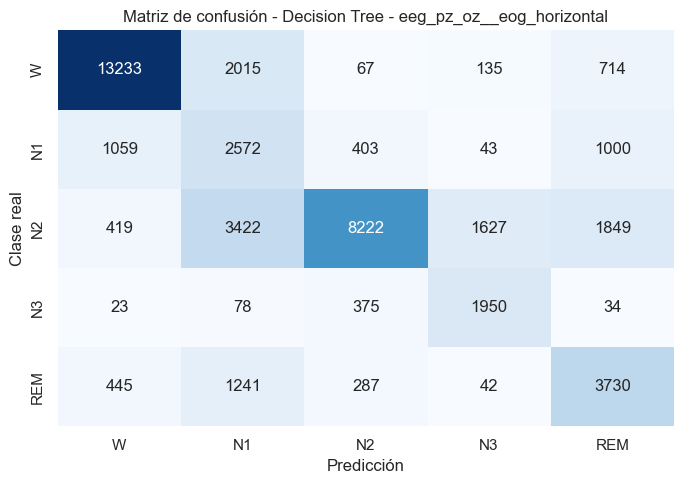

,W,N1,N2,N3,REM
W,13233,2015,67,135,714
N1,1059,2572,403,43,1000
N2,419,3422,8222,1627,1849
N3,23,78,375,1950,34
REM,445,1241,287,42,3730


In [29]:
plot_confusion_matrices("Decision Tree", dt_test_eval_df)

### Importancia de variables y guardado de artefactos

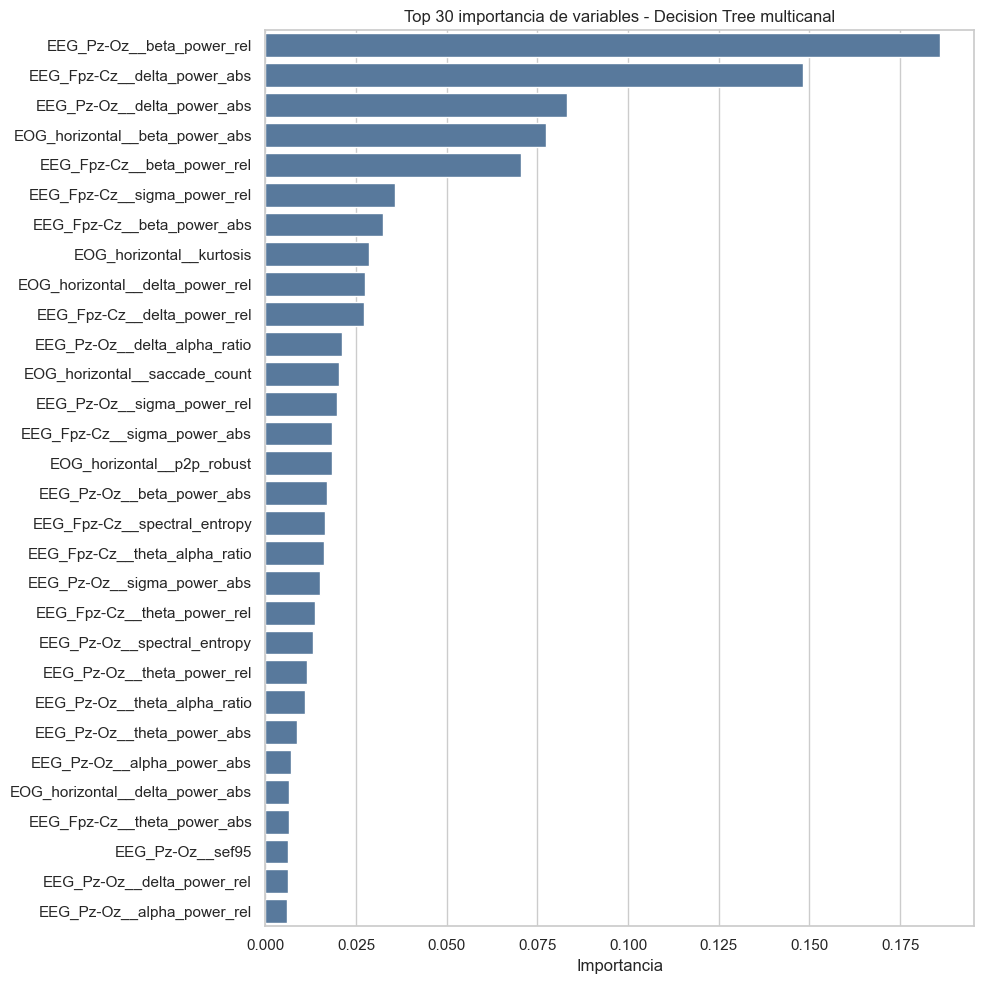

,feature,importance
17,EEG_Pz-Oz__beta_power_rel,0.186053
5,EEG_Fpz-Cz__delta_power_abs,0.148349
19,EEG_Pz-Oz__delta_power_abs,0.083291
28,EOG_horizontal__beta_power_abs,0.077286
3,EEG_Fpz-Cz__beta_power_rel,0.070436
9,EEG_Fpz-Cz__sigma_power_rel,0.035815
2,EEG_Fpz-Cz__beta_power_abs,0.032383
32,EOG_horizontal__kurtosis,0.028535
30,EOG_horizontal__delta_power_rel,0.027593
6,EEG_Fpz-Cz__delta_power_rel,0.027246


In [30]:
dt_feature_importance = plot_feature_importance("Decision Tree", dt_search.best_estimator_)

dt_paths = save_artifacts(
    "Decision Tree",
    "decision-tree",
    dt_search,
    dt_metrics,
    dt_metrics_by_combo,
    dt_per_class_by_combo,
    dt_feature_importance,
)

## Comparación de modelos

Resumen de las métricas en test y del mejor `f1_macro` de validación cruzada para los cuatro modelos. El ranking se ordena por `best_cv_macro_f1` en CV.

,model,best_cv_macro_f1,accuracy,macro_f1,balanced_accuracy,cohens_kappa,best_params
0,XGBoost,0.692192,0.716109,0.659114,0.704313,0.619530,"{'reg_lambda': 1.0, 'reg_alpha': 0.5, 'n_estim..."
1,LightGBM,0.690714,0.711659,0.654897,0.701491,0.613953,"{'reg_lambda': 0, 'reg_alpha': 0.01, 'num_leav..."
2,Random Forest,0.682119,0.706247,0.650260,0.695895,0.606661,"{'n_estimators': 100, 'min_samples_split': 100..."
3,Decision Tree,0.640419,0.650569,0.600139,0.651689,0.539790,"{'min_samples_split': 2, 'min_samples_leaf': 5..."


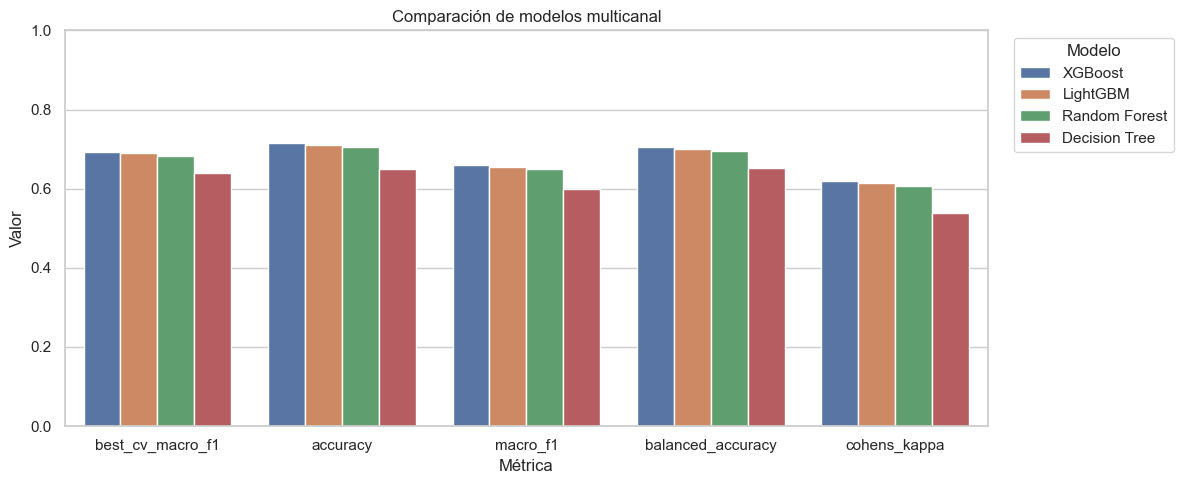

Mejor modelo por macro F1 en CV: XGBoost (CV 0.6922, test 0.6591)


In [41]:
comparison = pd.DataFrame(
    [
        {
            "model": model_name,
            "best_cv_macro_f1": result["metrics"]["best_cv_macro_f1"],
            "accuracy": result["metrics"]["accuracy"],
            "macro_f1": result["metrics"]["macro_f1"],
            "balanced_accuracy": result["metrics"]["balanced_accuracy"],
            "cohens_kappa": result["metrics"]["cohens_kappa"],
            "best_params": result["metrics"]["best_params"],
        }
        for model_name, result in results.items()
    ]
).sort_values("best_cv_macro_f1", ascending=False).reset_index(drop=True)

comparison.to_csv(COMPARISON_PATH, index=False)
display(comparison)

comparison_long = comparison.melt(
    id_vars="model",
    value_vars=["best_cv_macro_f1", "accuracy", "macro_f1", "balanced_accuracy", "cohens_kappa"],
    var_name="metric",
    value_name="value",
)

plt.figure(figsize=(12, 5))
sns.barplot(data=comparison_long, x="metric", y="value", hue="model")
plt.title("Comparación de modelos multicanal")
plt.xlabel("Métrica")
plt.ylabel("Valor")
plt.ylim(0, 1)
plt.legend(title="Modelo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

best_model_name = comparison.loc[0, "model"]
print(
    f"Mejor modelo por macro F1 en CV: {best_model_name} "
    f"(CV {comparison.loc[0, 'best_cv_macro_f1']:.4f}, test {comparison.loc[0, 'macro_f1']:.4f})"
)

model,Decision Tree,LightGBM,Random Forest,XGBoost
channel_combo,,,,
eeg_fpz_cz,0.570095,0.613348,0.600477,0.617667
eeg_fpz_cz__eeg_pz_oz,0.609193,0.667523,0.664550,0.673290
eeg_fpz_cz__eeg_pz_oz__eog_horizontal,0.641078,0.707389,0.699972,0.711439
eeg_fpz_cz__eog_horizontal,0.627340,0.682278,0.676650,0.690246
eeg_pz_oz,0.539782,0.589907,0.597709,0.591759
eeg_pz_oz__eog_horizontal,0.611214,0.670256,0.666375,0.671709
overall,0.600139,0.654897,0.650260,0.659114


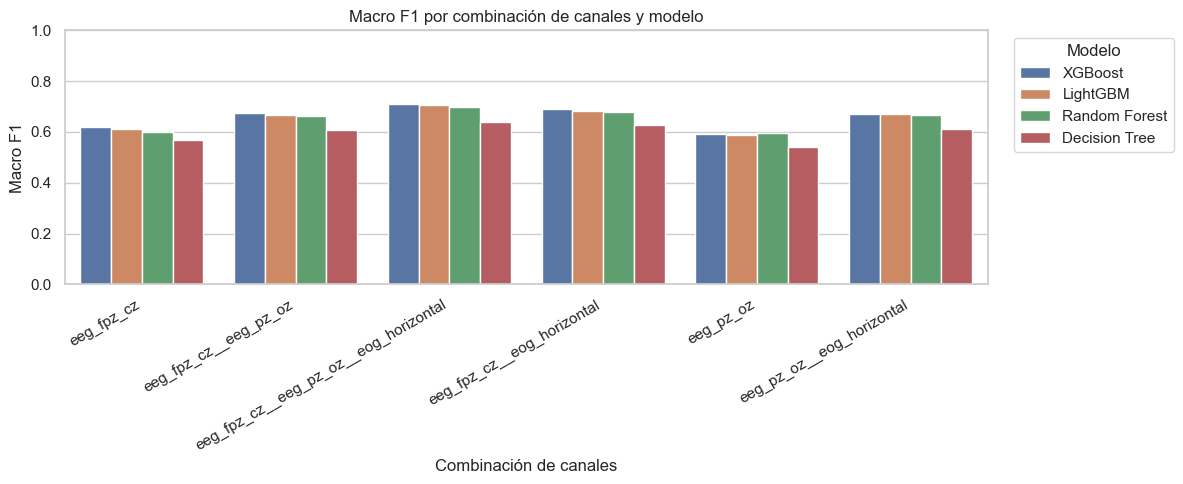

In [42]:
comparison_by_combo = pd.concat(
    [
        result["metrics_by_combo"].assign(model=model_name)
        for model_name, result in results.items()
    ],
    ignore_index=True,
)
comparison_by_combo.to_csv(COMPARISON_BY_COMBO_PATH, index=False)

display(
    comparison_by_combo.pivot(index="channel_combo", columns="model", values="macro_f1")
)

plt.figure(figsize=(12, 5))
sns.barplot(
    data=comparison_by_combo[comparison_by_combo["channel_combo"] != "overall"],
    x="channel_combo",
    y="macro_f1",
    hue="model",
)
plt.title("Macro F1 por combinación de canales y modelo")
plt.xlabel("Combinación de canales")
plt.ylabel("Macro F1")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.legend(title="Modelo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Registro en MLflow

Cada modelo se registra como un *run* en el experimento `sleep-staging-baseline-multicanal`, el mismo que usa `09_best_model_xgboost_multicanal.ipynb`. Los datos se leen de los artefactos guardados arriba (`.joblib` y `model_info_<modelo>_multicanal.json`), así que no hace falta reentrenar. Basta con ejecutar antes las celdas de configuración, carga y preparación de matrices.

Por cada modelo se registran:

- **Parámetros:** mejores hiperparámetros y configuración de la búsqueda.
- **Métricas:** globales en test, `best_cv_macro_f1` y métricas por combinación de canales (p. ej. `macro_f1__eeg_pz_oz`).
- **Artefactos:** matriz de confusión, CSV/JSON de métricas e importancia de variables y el bundle `.joblib` de inferencia.
- **Modelo:** en formato `mlflow.sklearn` (serializado con `cloudpickle`) y registrado en el Model Registry como `sleep-staging-<modelo>-multicanal`.

Se usa `mlflow.sklearn.log_model` también para XGBoost porque `mlflow.xgboost.log_model` llama a `XGBClassifier.save_model()`, que falla con scikit-learn >= 1.8 (`_estimator_type` undefined).

**Requisitos:** `MLFLOW_TRACKING_URI` definido en `.env` (ver `.env.example`) y credenciales de AWS configuradas, porque el servidor guarda los artefactos en S3. Sin credenciales, parámetros y métricas se registran, pero la subida de artefactos falla.

In [35]:
load_dotenv(PROJECT_ROOT / ".env")

MLFLOW_TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI")
MLFLOW_EXPERIMENT_NAME = "sleep-staging-baseline-multicanal"
REGISTER_MODELS = True

os.environ.setdefault("MLFLOW_ENABLE_PROXY_MULTIPART_UPLOAD", "true")
os.environ.setdefault("MLFLOW_MULTIPART_UPLOAD_MINIMUM_FILE_SIZE", str(50 * 1024**2))
os.environ.setdefault("MLFLOW_HTTP_REQUEST_TIMEOUT", "600")
os.environ.setdefault("MLFLOW_ARTIFACT_UPLOAD_DOWNLOAD_TIMEOUT", "1800")

MAX_EXTRA_ARTIFACT_MB = 100

MODELS_TO_LOG = {
    "XGBoost": "xgboost",
    "LightGBM": "lightgbm",
    "Random Forest": "random-forest",
    "Decision Tree": "decision-tree",
}

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
experiment = mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)

print(f"Tracking URI: {MLFLOW_TRACKING_URI}")
print(f"Experiment: {experiment.name}")

Tracking URI: https://18.119.196.100
Experiment: sleep-staging-baseline-multicanal


In [36]:
mlflow_label_ids = label_encoder.transform(class_labels)
combo_metric_names = ["accuracy", "macro_f1", "balanced_accuracy", "cohens_kappa"]
mlflow_runs = {}
mlflow_failed = {}

for model_name, model_slug in MODELS_TO_LOG.items():
    paths = get_artifact_paths(model_slug)
    if not paths["joblib"].exists():
        print(f"[{model_name}] No se encontró {paths['joblib']}; se omite.")
        continue

    bundle = joblib.load(paths["joblib"])
    with open(paths["info"]) as f:
        info = json.load(f)

    model = bundle["model"]
    y_pred_mlflow = model.predict(X_test[bundle["feature_columns"]])

    try:
        with mlflow.start_run(experiment_id=experiment.experiment_id, run_name=f"{model_slug}_multicanal") as run:
            mlflow.set_tags(
                {
                    "model_type": "baseline",
                    "model_family": model_name,
                    "signals_used": "EEG Fpz-Cz y/o EEG Pz-Oz + EOG horizontal (opcional)",
                    "stage": "hyperparameter_search",
                    "notebook": "08_train_base_models_multichannel",
                }
            )

            mlflow.log_params(info["best_params"])
            mlflow.log_params(
                {
                    "cv_splits": CV_SPLITS,
                    "n_iter_search": N_ITER_SEARCH,
                    "scoring": SCORING,
                    "num_class": len(class_labels),
                    "n_features": len(bundle["feature_columns"]),
                    "excluded_id_columns": ",".join(ID_COLUMNS),
                    "excluded_control_columns": ",".join(CONTROL_COLUMNS),
                    "categorical_columns": ",".join(CATEGORICAL_COLUMNS),
                }
            )

            mlflow.log_metrics(
                {
                    "accuracy": info["accuracy"],
                    "macro_f1": info["macro_f1"],
                    "balanced_accuracy": info["balanced_accuracy"],
                    "cohens_kappa": info["cohens_kappa"],
                    "best_cv_macro_f1": info["best_cv_macro_f1"],
                }
            )

            for row in info["metrics_by_channel_combo"]:
                if row["channel_combo"] == "overall":
                    continue
                mlflow.log_metrics(
                    {f"{metric}__{row['channel_combo']}": row[metric] for metric in combo_metric_names}
                )

            conf_matrix_df = pd.DataFrame(
                confusion_matrix(y_test, y_pred_mlflow, labels=mlflow_label_ids),
                index=class_labels,
                columns=class_labels,
            )
            fig, ax = plt.subplots(figsize=(8, 6))
            sns.heatmap(conf_matrix_df, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
            ax.set_title(f"Matriz de confusión - {model_name} multicanal")
            ax.set_xlabel("Predicción")
            ax.set_ylabel("Clase real")
            fig.tight_layout()
            mlflow.log_figure(fig, "confusion_matrix_test.png")
            plt.close(fig)

            for artifact_key in ["info", "metrics_by_combo", "per_class_by_combo", "feature_importance", "joblib"]:
                artifact_mb = paths[artifact_key].stat().st_size / 1024**2
                if artifact_key == "joblib" and artifact_mb > MAX_EXTRA_ARTIFACT_MB:
                    print(f"[{model_name}] Se omite {paths[artifact_key].name} ({artifact_mb:.0f} MB) como artefacto extra.")
                    continue
                mlflow.log_artifact(str(paths[artifact_key]), artifact_path="files")

            mlflow.sklearn.log_model(
                sk_model=model,
                name="model",
                serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_CLOUDPICKLE,
                input_example=X_test[bundle["feature_columns"]].head(5),
                registered_model_name=f"sleep-staging-{model_slug}-multicanal" if REGISTER_MODELS else None,
            )

            mlflow_runs[model_name] = run.info.run_id
            print(f"[{model_name}] registrado en MLflow. run_id: {run.info.run_id}")
    except Exception as exc:
        mlflow_failed[model_name] = f"{type(exc).__name__}: {exc}"
        print(f"[{model_name}] falló el registro: {mlflow_failed[model_name][:500]}")

display(pd.Series(mlflow_runs, name="run_id"))
if mlflow_failed:
    display(pd.Series(mlflow_failed, name="error"))

2026/11/11 12:35:20 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
Registered model 'sleep-staging-xgboost-multicanal' already exists. Creating a new version of this model...
2026/11/11 12:35:26 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: sleep-staging-xgboost-multicanal, version 3
Created version '3' of model 'sleep-staging-xgboost-multicanal'.


[XGBoost] registrado en MLflow. run_id: eb94667a00ea4a7cbcc60db80a88e3b9
🏃 View run xgboost_multicanal at: https://18.119.196.100/#/experiments/4/runs/eb94667a00ea4a7cbcc60db80a88e3b9
🧪 View experiment at: https://18.119.196.100/#/experiments/4


2026/11/11 12:35:36 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
Registered model 'sleep-staging-lightgbm-multicanal' already exists. Creating a new version of this model...
2026/11/11 12:35:39 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: sleep-staging-lightgbm-multicanal, version 3
Created version '3' of model 'sleep-staging-lightgbm-multicanal'.


[LightGBM] registrado en MLflow. run_id: 27623cb37b0847ee8f421d35bef5c897
🏃 View run lightgbm_multicanal at: https://18.119.196.100/#/experiments/4/runs/27623cb37b0847ee8f421d35bef5c897
🧪 View experiment at: https://18.119.196.100/#/experiments/4


2026/11/11 12:35:57 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
Registered model 'sleep-staging-random-forest-multicanal' already exists. Creating a new version of this model...
2026/11/11 12:36:13 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: sleep-staging-random-forest-multicanal, version 2
Created version '2' of model 'sleep-staging-random-forest-multicanal'.


[Random Forest] registrado en MLflow. run_id: 1ce3fe25ee4c4291867ac35cd5070f60
🏃 View run random-forest_multicanal at: https://18.119.196.100/#/experiments/4/runs/1ce3fe25ee4c4291867ac35cd5070f60
🧪 View experiment at: https://18.119.196.100/#/experiments/4


2026/11/11 12:36:22 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
Registered model 'sleep-staging-decision-tree-multicanal' already exists. Creating a new version of this model...
2026/11/11 12:36:25 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: sleep-staging-decision-tree-multicanal, version 2
Created version '2' of model 'sleep-staging-decision-tree-multicanal'.


[Decision Tree] registrado en MLflow. run_id: 32cc82c89f0640d285b45646d3d6ca23
🏃 View run decision-tree_multicanal at: https://18.119.196.100/#/experiments/4/runs/32cc82c89f0640d285b45646d3d6ca23
🧪 View experiment at: https://18.119.196.100/#/experiments/4


XGBoost          eb94667a00ea4a7cbcc60db80a88e3b9
LightGBM         27623cb37b0847ee8f421d35bef5c897
Random Forest    1ce3fe25ee4c4291867ac35cd5070f60
Decision Tree    32cc82c89f0640d285b45646d3d6ca23
Name: run_id, dtype: object